# 2025.2.26 WXY_01_Basic

In [1]:
import anndata as ad
import matplotlib.pyplot as plt
import muon as mu
import pandas as pd
import scanpy as sc
import numpy as np
import scirpy as ir
import seaborn as sns
import matplotlib as mpl
import matplotlib.ticker as ticker
import os
from scipy.sparse import csc_matrix, csr_matrix
mpl.rcParams['font.family'] = 'Arial'
figPath = "WXY-figure-2.26"
plt.rcParams["font.sans-serif"] = ["Arial"]
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["font.size"] = 14

In [6]:
def anno(adata:ad.AnnData, annoDict:dict, obsKey='cnv_status', obsVal='cnv_leiden', default="Unknown"):
  if default is not None:
    adata.obs[obsKey] = default
  for key in annoDict.keys():
    adata.obs.loc[adata.obs[obsVal].isin(annoDict[key]), obsKey] = key
  return adata

In [2]:
adata_merged = sc.read_h5ad("/home/rzh/GSE165816_basic.h5ad")

/home/rzh/miniconda3/lib/python3.11/site-packages/anndata/_core/anndata.py:1791: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


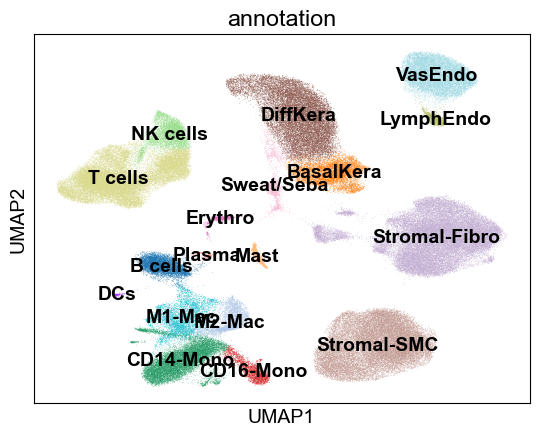

In [7]:
annot = {
  'Stromal-Fibro': ['0', '3', '18', '23', '26'],
  'Stromal-SMC': ['1', '8'],
  'M1-Mac': ['13'],
  'M2-Mac': ['14'],
  'CD16-Mono': ['16'],
  'CD14-Mono': ['4', '22','24'],
  'DCs': ['27'],
  'Plasma': ['25'],
  'Erythro': ['21'],
  'VasEndo': ['5'],
  'LymphEndo': ['19'],
  'Sweat/Seba': ['17'],
  'T cells': ['2', '15', '10'],
  'NK cells': ['12'],
  'B cells': ['11'],
  'DiffKera': ['6', '7'],
  'BasalKera': ['9'],
  'Mast': ['20']
}
adata_merged = anno(adata_merged, annot, 'annotation', 'leiden-1')
sc.pl.umap(adata_merged, color=['annotation'], legend_loc='on data')

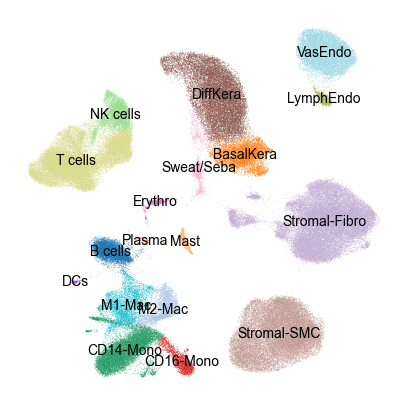

In [8]:
fig, ax = plt.subplots(1, 1, figsize=(5, 5))
sc.pl.umap(adata_merged, color=['annotation'], legend_loc='on data', legend_fontsize=10, legend_fontweight=1,
           title='', ax=ax, show=False)
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.set_xlabel("")
ax.set_ylabel("")
fig.savefig(f'{figPath}/Total-anno_UMAP.png', dpi=400, bbox_inches='tight')

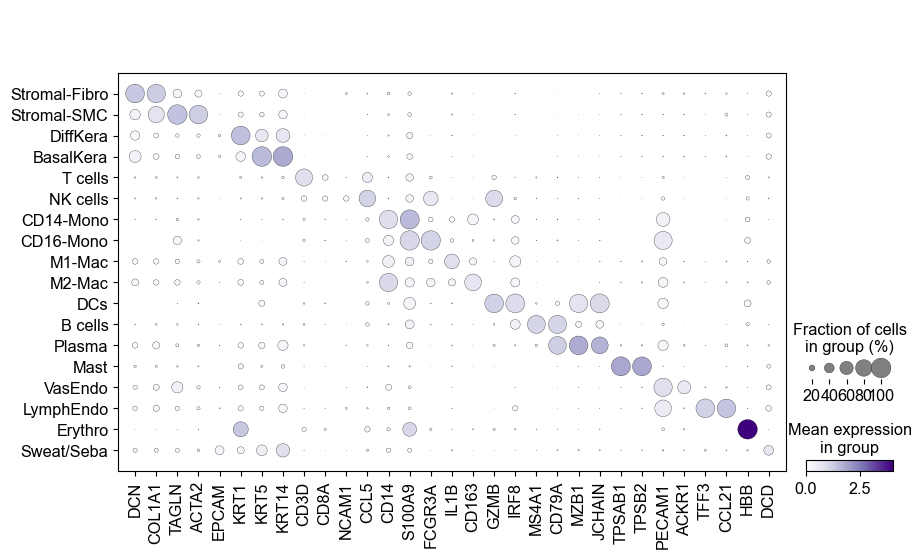

In [511]:
fig, ax = plt.subplots(1,1,figsize=(10,6))
sc.pl.dotplot(adata_merged, groupby='annotation',  cmap='Purples', var_names=[
  'DCN', 'COL1A1', 'TAGLN', 'ACTA2','EPCAM','KRT1','KRT5', 'KRT14',
  'CD3D', 'CD8A', 'NCAM1', 'CCL5', 'CD14', 'S100A9','FCGR3A', 'IL1B', 'CD163', 'GZMB', 'IRF8',
  'MS4A1', 'CD79A', 'MZB1', 'JCHAIN','TPSAB1', 'TPSB2',
  'PECAM1', 'ACKR1', 'TFF3', 'CCL21', 'HBB', 'DCD',], 
  categories_order=['Stromal-Fibro', 'Stromal-SMC', 'DiffKera', 'BasalKera', 
                    'T cells','NK cells',  'CD14-Mono', 'CD16-Mono', 'M1-Mac', 'M2-Mac','DCs',
                    'B cells', 'Plasma', 'Mast', 'VasEndo', 'LymphEndo',  'Erythro', 'Sweat/Seba'],ax=ax)
ax.set_xticklabels(ax.get_xticklabels(), fontsize=8)
fig.savefig(f"{figPath}/Total-markers.pdf", bbox_inches='tight')

In [13]:
annot = {
  'H': ['G1', 'G20', 'G16', 'G18', 'G26', 'G28', 'G29', 'G30', 'G31', 'G32', 'G36', 'G50', 'G10', 'G24', 'G14', 'G43', 'G44', 'G40'],
  'DM': ['G2A', 'G4A', 'G19', 'G46', 'G48', 'G47', 'G38', 'G41', 'G1A', 'G3A', 'G3', 'G5'],
  'DFU-H': ['G4', 'G23', 'G12', 'G22', 'G2', 'G13', 'G25', 'G15', 'G17', 'G27', 'G7', 'G8', 'G49', 'G42', 'G45'],
  'DFU-NH': ['G6', 'G11', 'G21', 'G9', 'G35', 'G37', 'G33', 'G34', 'G39']
}
adata_merged = anno(adata_merged, annot, 'group', 'batch')

In [14]:
annot = {
  'Foot Skin': [
    'G6','G4', 'G23','G2','G15', 'G9', 'G33', 'G34','G39', 'G7', 'G8',
    'G49','G42','G45', 'G2A', 'G46', 'G38', 'G41', 'G1A', 'G3A', 'G3', 'G5', 
    'G16', 'G28', 'G31', 'G32', 'G50', 'G10', 'G24', 'G14', 'G43', 'G40', 'G44', 
  ],
  'Forearm Biopsy': [
    'G11', 'G12', 'G13', 'G17', 'G35', 'G4A', 'G48', 'G1', 'G18', 'G29', 'G36'
  ],
  'PBMC': [
    'G21',  'G22', 'G25', 'G27', 'G37', 'G19', 'G47', 'G20', 'G26', 'G30'
  ]
}
adata_merged = anno(adata_merged, annot, 'tissue', 'batch')

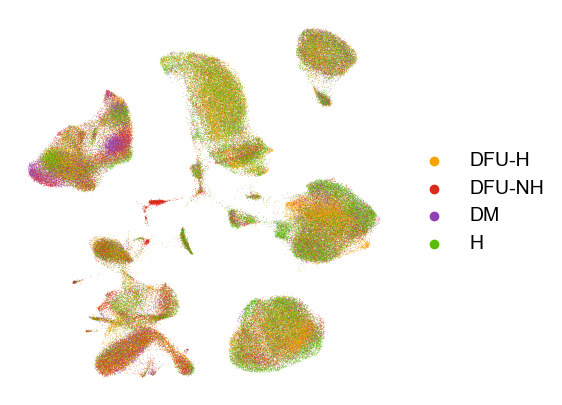

In [32]:
fig, ax = plt.subplots(1, 1, figsize=(5, 5))
sc.pl.umap(adata_merged, color=['group'], palette=['#f6a300', '#db291a', '#923fb8', '#57bd03'],
           title='', ax=ax, show=False)
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.set_xlabel("")
ax.set_ylabel("")
fig.savefig(f'{figPath}/FigS1a.png', dpi=400, bbox_inches='tight')

In [19]:
# ---------------------------------------------------------
# Custom Function: Stacked Bar Plot for Cell Proportions
# ---------------------------------------------------------
# This function visualizes the relative abundance of different 
# cell types (or groups) across samples (e.g., Patients).
# 
# Key Features:
# 1. Normalization: Automatically normalizes raw counts to percentages (0-100%).
# 2. Stacking: Uses cumulative sums to stack bars correctly.
# 3. Formatting: 
#    - Y-axis is formatted as percentages.
#    - Legend is placed outside the plot (bottom) for clarity.
#    - Spines (top/right) are removed for a cleaner look.
# ---------------------------------------------------------
def propPlot(age_df, barlabels, ax, colors=sc.pl.palettes.default_20, xlabel='Patient ID', show_y=True, xrotate=90):
    all_df = age_df.sum(axis=1)
    age_normdf = pd.DataFrame([age_df.loc[i,:]/all_df[i] for i in barlabels], index=barlabels)
    age_cumdf = pd.DataFrame([np.cumsum(age_normdf.loc[i,:]) for i in barlabels], index=barlabels)
    norm_gdfs = age_normdf
    cum_gdfs = age_cumdf
    for i, col in enumerate(age_df.columns):
        height = norm_gdfs[col]
        starts = cum_gdfs[col] - height
        rects = ax.bar(barlabels, height, bottom=starts, width=0.9, color=colors[i], edgecolor='white', linewidth=0.5,
                        label=col, alpha=1)
    
        # ax.bar_label(rects,age_df.loc[:, col], label_type='center', color='lightgrey', fontsize=14)
    ax.legend( bbox_to_anchor=(1, -0.3), 
              handletextpad=0.5, frameon=False,
                          borderpad=0.4,
                          columnspacing=1,
                          handlelength=0.65,
              loc='lower left')
    if show_y:
        ax.yaxis.set_major_formatter(ticker.PercentFormatter(xmax=1,decimals=0))
        ax.set_ylabel('Cell proportions')
    else:
        ax.yaxis.set_visible(False)
        ax.spines.left.set_visible(False)
    ax.set_xlabel(xlabel)
    ax.set_xticks(barlabels)
    ax.set_xticklabels(labels=barlabels,rotation=xrotate)
    ax.spines.top.set_visible(False)
    ax.spines.right.set_visible(False)

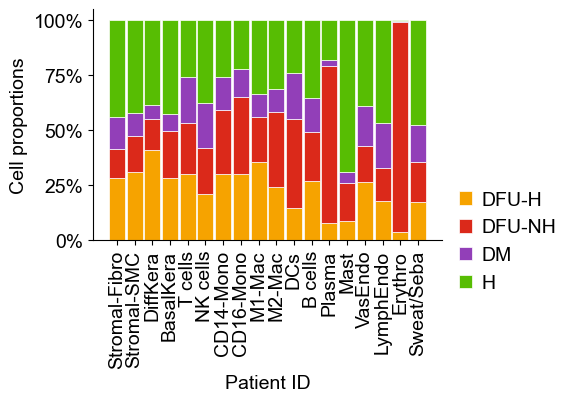

In [20]:
# -----------------------------------------------------------------------------
# Data Preparation & Plotting: NK Cell Proportions across Patients
# -----------------------------------------------------------------------------
# 1. Define specific sample batches (barlabels) to visualize.
# 2. Extract unique cell types from the 'anno-pca' annotation.
# 3. Construct 'age_df': A DataFrame where rows are samples and columns are cell types,
#    containing the raw counts of cells for each combination.
#
# Note on Labeling:
# To clearly distinguish patient samples from NK cell cluster IDs (e.g., NK1_0),
# we format the X-axis labels with a 'P' prefix (e.g., P01_0) in the final plot.
# -----------------------------------------------------------------------------
barlabels = ['Stromal-Fibro', 'Stromal-SMC', 'DiffKera', 'BasalKera', 
                    'T cells','NK cells',  'CD14-Mono', 'CD16-Mono', 'M1-Mac', 'M2-Mac','DCs',
                    'B cells', 'Plasma', 'Mast', 'VasEndo', 'LymphEndo',  'Erythro', 'Sweat/Seba']
cell_types = list(adata_merged.obs['group'].unique())
cell_types.sort()
age_df = pd.DataFrame(columns = list(cell_types))
for bar in barlabels:
    d1 = pd.DataFrame([len(adata_merged[(adata_merged.obs["group"] == ct) & (adata_merged.obs["annotation"] == bar)]) for ct in list(cell_types)], index = list(cell_types), columns=[bar]).T
    age_df = pd.concat([age_df, d1])
fig0, ax0 = plt.subplots(figsize=(4.5, 3))
propPlot(age_df, ax=ax0, barlabels=barlabels, colors=['#f6a300', '#db291a', '#923fb8', '#57bd03'])
# ax0.set_xticklabels(['P01_0', 'P02_0', 'P03_0', 'P04_0','P05_0', 
#              'P06_0','P07_0',  'P08_0', 'P09_0','P10_0', 
#              'P11_0','P05_1', 'P06_1','P07_1', 'P08_1',
#              'P11_1', 'B09_0', 'R06_0'])
fig0.savefig(f"{figPath}/FigS1b.pdf",bbox_inches='tight')

In [22]:
adata_concat = sc.read_h5ad("/home/rzh/reclustered_adata_test_42_rsc.h5ad")
adata_concat

/home/rzh/miniconda3/lib/python3.11/site-packages/anndata/_core/anndata.py:1791: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


AnnData object with n_obs × n_vars = 60727 × 24238
    obs: 'batch', 'mt_frac', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'n_genes', 'n_counts', 'doublet_score', 'predicted_doublet', 'leiden-1', 'condition_l0', 'condition_l1', 'condition_l2', 'condition_raw', 'manual_selected', 'LassoARE_selected', 'LassoARE_clusters', 'leiden', 'group', 'tissue', 'anno-Fib'
    var: 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'LassoARE_clusters_colors', 'LassoARE_pca', 'anno-Fib_colors', 'batch_colors', 'condition_l0_colors', 'condition_l1_colors', 'condition_l2_colors', 'dendrogram_LassoARE_clusters', 'group_colors', 'hvg', 'leiden', 'leiden-1', 'leiden-1_colors', 'leiden_colors', 'log1p', 'manual_selected_colors', 'neighbors', 'pca', 'rank_genes_groups', 'scrublet', 'tissue_colors', 'umap'
    obsm: '

In [91]:
annot = {
  'H': ['G1', 'G20', 'G16', 'G18', 'G26', 'G28', 'G29', 'G30', 'G31', 'G32', 'G36', 'G50', 'G10', 'G24', 'G14', 'G43', 'G44', 'G40'],
  'DM': ['G2A', 'G4A', 'G19', 'G46', 'G48', 'G47', 'G38', 'G41', 'G1A', 'G3A', 'G3', 'G5'],
  'DFU-H': ['G4', 'G23', 'G12', 'G22', 'G2', 'G13', 'G25', 'G15', 'G17', 'G27', 'G7', 'G8', 'G49', 'G42', 'G45'],
  'DFU-NH': ['G6', 'G11', 'G21', 'G9', 'G35', 'G37', 'G33', 'G34', 'G39']
}
adata_concat = anno(adata_concat, annot, 'group', 'batch')

In [ ]:
annot = {
  'Foot Skin': [
    'G6','G4', 'G23','G2','G15', 'G9', 'G33', 'G34','G39', 'G7', 'G8',
    'G49','G42','G45', 'G2A', 'G46', 'G38', 'G41', 'G1A', 'G3A', 'G3', 'G5', 
    'G16', 'G28', 'G31', 'G32', 'G50', 'G10', 'G24', 'G14', 'G43', 'G40', 'G44', 
  ],
  'Forearm Biopsy': [
    'G11', 'G12', 'G13', 'G17', 'G35', 'G4A', 'G48', 'G1', 'G18', 'G29', 'G36'
  ],
  'PBMC': [
    'G21',  'G22', 'G25', 'G27', 'G37', 'G19', 'G47', 'G20', 'G26', 'G30'
  ]
}
adata_concat = anno(adata_concat, annot, 'tissue', 'batch')

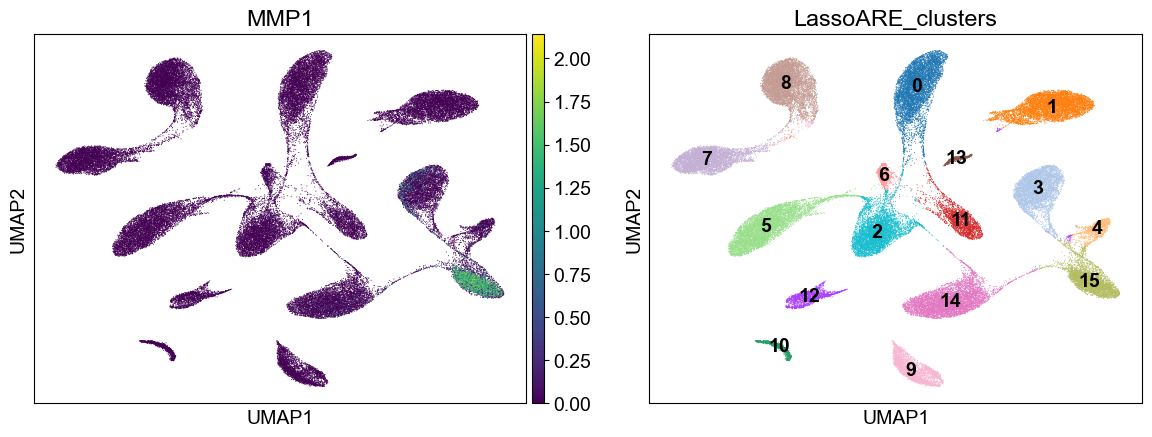

In [101]:
adata_concat.obs['LassoARE_clusters'] = adata_concat.obs['LassoARE_clusters'].astype('str')
adata_concat.obs['LassoARE_clusters'] = adata_concat.obs['LassoARE_clusters'].astype('category')
sc.pl.umap(adata_concat, color=['MMP1', 'LassoARE_clusters'], legend_loc='on data')

In [144]:
annot = {
  'APOD+ Fibro': ['1'],
  'WISP2+ Fibro': ['12'],
  'Melanocytes': ['10'],
  'Schwann Cells': ['13'],
  'MMP1+ Effector Fibro': ['15'],
  'TNC+ Matrisynthetic Fibro': ['3'],
  'IGF1+ Regenerative Fibro': ['4'],
  'NDUFA4L2+ Hypoxia Fibro': ['14'],
  'CCL19+ Inflammatory Fibro': ['6'],
  'APCDD1+ Fibro': ['7'],
  'AP-Fibro': ['8'],
  'Papillary Fibro': ['9'],
  'SMC1': ['0'],
  'SMC2': ['2'],
  'SMC3': ['11'],
  'SMC4': ['5'],
  'SMC5': ['14'],
}
adata_concat = anno(adata_concat, annot, 'anno-Fib', 'LassoARE_clusters')

In [23]:
annot = {
  '01: APOD+ Fibro': ['1'],
  '02: APCDD1+ Fibro': ['7'],
  '03: AP-Fibro': ['8'],
  '04: Papillary Fibro': ['9'],
  '05: WISP2+ Fibro': ['12'],
  '06: MMP1+ Effector Fibro': ['15'],
  '07: TNC+ Matrisynthetic Fibro': ['3'],
  '08: IGF1+ Regenerative Fibro': ['4'],
  '09: CCL19+ Inflammatory Fibro': ['6'],
  '10: SMC1': ['0'],
  '11: SMC2': ['2'],
  '12: SMC3': ['11'],
  '13: SMC4': ['5'],
  '14: SMC5': ['14'],
  '15: Melanocytes': ['10'],
  '16: Schwann Cells': ['13'],
}
adata_concat = anno(adata_concat, annot, 'anno-Fib-number', 'LassoARE_clusters')

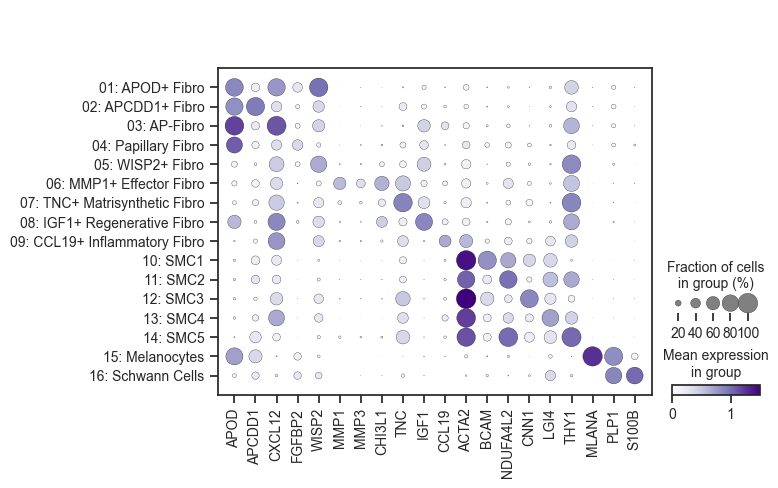

In [542]:
fig, ax = plt.subplots(1,1,figsize=(7,5))
sns.set_style('ticks')
sc.pl.dotplot(adata_concat, groupby='anno-Fib-number',  cmap='Purples', var_names=[
  'APOD', 'APCDD1', 'CXCL12', 'FGFBP2', 'WISP2', 'MMP1', 'MMP3','CHI3L1','TNC', 'IGF1', 'CCL19', 'ACTA2', 'BCAM', 'NDUFA4L2', 'CNN1', 'LGI4', 'THY1', 'MLANA', 'PLP1', 'S100B'], ax=ax)
ax.set_xticklabels(ax.get_xticklabels(), fontsize=8)
fig.savefig(f"{figPath}/Stromal-markers.pdf", bbox_inches='tight')

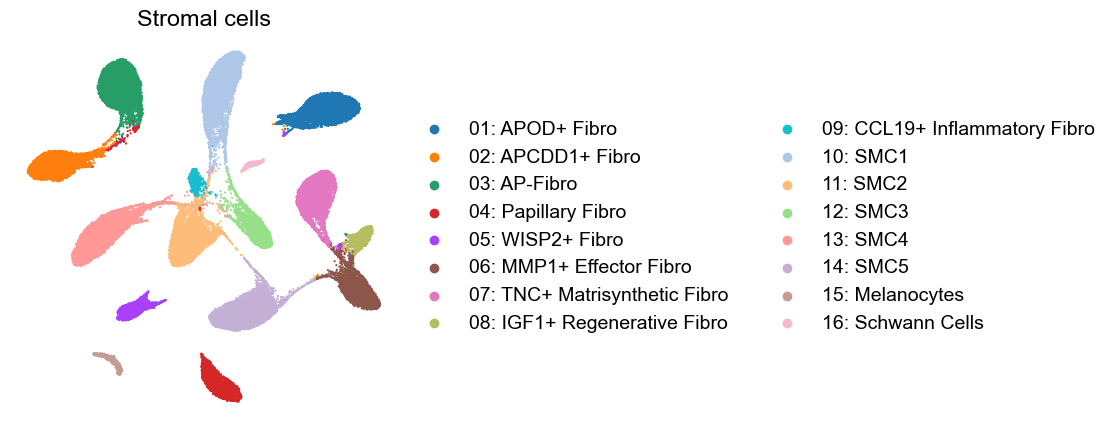

In [475]:
fig, ax = plt.subplots(1, 1, figsize=(5, 5))
sc.pl.umap(adata_concat, color=['anno-Fib-number'],size=10,
           title='Stromal cells', ax=ax, show=False)
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.set_xlabel("")
ax.set_ylabel("")
fig.savefig(f'{figPath}/Fib-anno_UMAP.png', dpi=400, bbox_inches='tight')


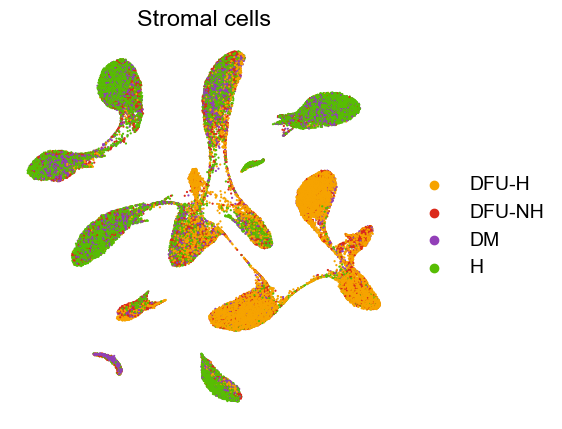

In [24]:
fig, ax = plt.subplots(1, 1, figsize=(5, 5))
sc.pl.umap(adata_concat, color=['group'],size=10, palette=['#f6a300', '#db291a', '#923fb8', '#57bd03'],
           title='Stromal cells', ax=ax, show=False)
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.set_xlabel("")
ax.set_ylabel("")
fig.savefig(f'{figPath}/Fib-group_UMAP.png', dpi=400, bbox_inches='tight')

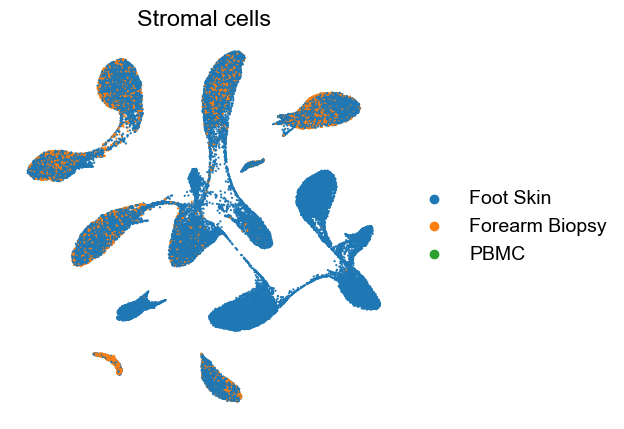

In [478]:
fig, ax = plt.subplots(1, 1, figsize=(5, 5))
sc.pl.umap(adata_concat, color=['tissue'],size=10,
           title='Stromal cells', ax=ax, show=False)
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.set_xlabel("")
ax.set_ylabel("")
fig.savefig(f'{figPath}/Fib-tissue_UMAP.png', dpi=400, bbox_inches='tight')

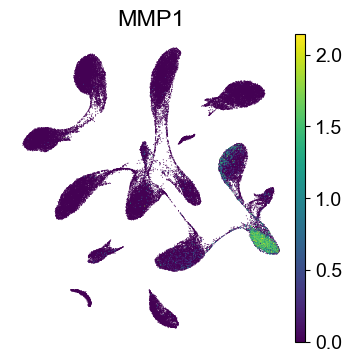

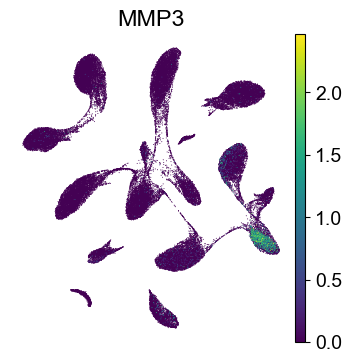

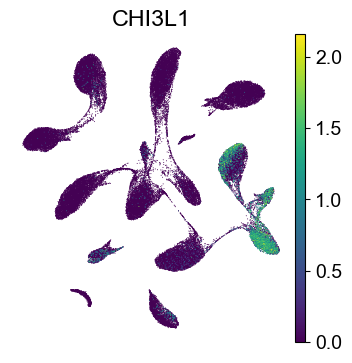

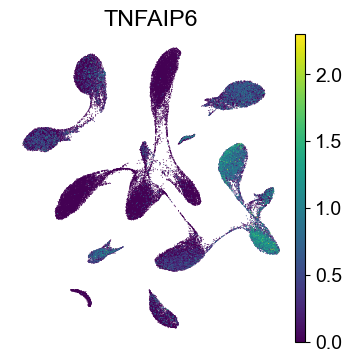

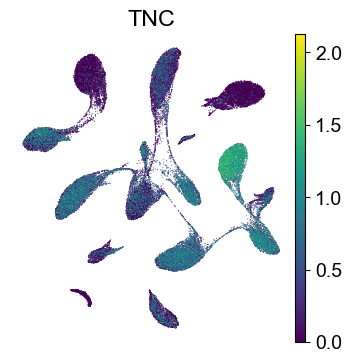

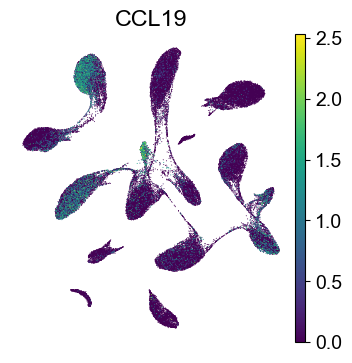

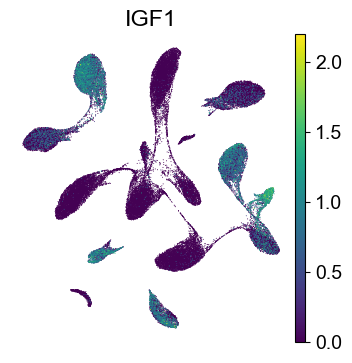

In [479]:
for gene in ['MMP1', 'MMP3', 'CHI3L1','TNFAIP6', 'TNC', 'CCL19', 'IGF1']:
  fig, ax = plt.subplots(1, 1, figsize=(4, 4))
  sc.pl.umap(adata_concat, color=gene,
           title=gene, ax=ax, show=False)
  ax.spines['right'].set_visible(False)
  ax.spines['top'].set_visible(False)
  ax.spines['left'].set_visible(False)
  ax.spines['bottom'].set_visible(False)
  ax.set_xlabel("")
  ax.set_ylabel("")
  # ax.legend(  handletextpad=0.5, frameon=False,
  #                     borderpad=0.6,
  #                     columnspacing=1.3,
  #                     handlelength=0.65, fontsize=12)
  fig.savefig(f"{figPath}/UMAP-{gene}.png", dpi=400, bbox_inches='tight')

In [548]:
adata_merged

AnnData object with n_obs × n_vars = 165857 × 24238
    obs: 'batch', 'mt_frac', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'n_genes', 'n_counts', 'doublet_score', 'predicted_doublet', 'leiden-1', 'group', 'annotation'
    var: 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'hvg', 'leiden-1', 'leiden-1_colors', 'log1p', 'neighbors', 'pca', 'scrublet', 'umap', 'rank_genes_groups', 'dendrogram_leiden-1', 'annotation_colors', 'dendrogram_annotation'
    obsm: 'X_pca', 'X_pca_harmony', 'X_umap'
    varm: 'PCs'
    layers: 'Raw'
    obsp: 'connectivities', 'distances'

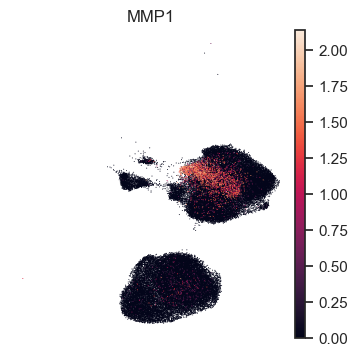

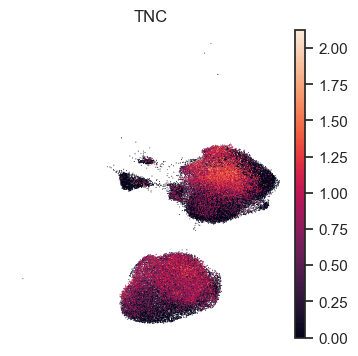

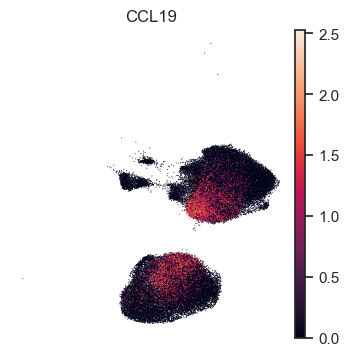

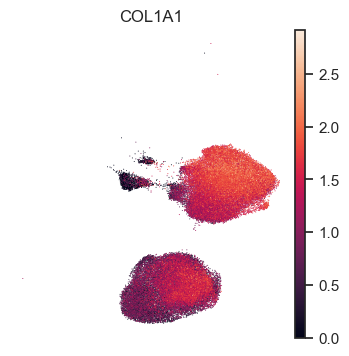

In [547]:
for gene in ['MMP1', 'TNC', 'CCL19','COL1A1']:
  fig, ax = plt.subplots(1, 1, figsize=(4, 4))
  sc.pl.umap(adata_merged[adata_merged.obs['annotation'].isin(['Stromal-Fibro', 'Stromal-SMC'])], color=gene,
           title=gene, ax=ax, show=False)
  ax.spines['right'].set_visible(False)
  ax.spines['top'].set_visible(False)
  ax.spines['left'].set_visible(False)
  ax.spines['bottom'].set_visible(False)
  ax.set_xlabel("")
  ax.set_ylabel("")
  # ax.legend(  handletextpad=0.5, frameon=False,
  #                     borderpad=0.6,
  #                     columnspacing=1.3,
  #                     handlelength=0.65, fontsize=12)
  fig.savefig(f"{figPath}/Fib-UMAP-{gene}.png", dpi=400, bbox_inches='tight')

In [155]:
# ---------------------------------------------------------
# Custom Function: Stacked Bar Plot for Cell Proportions
# ---------------------------------------------------------
# This function visualizes the relative abundance of different 
# cell types (or groups) across samples (e.g., Patients).
# 
# Key Features:
# 1. Normalization: Automatically normalizes raw counts to percentages (0-100%).
# 2. Stacking: Uses cumulative sums to stack bars correctly.
# 3. Formatting: 
#    - Y-axis is formatted as percentages.
#    - Legend is placed outside the plot (bottom) for clarity.
#    - Spines (top/right) are removed for a cleaner look.
# ---------------------------------------------------------
def propPlot(age_df, barlabels, ax, colors=sc.pl.palettes.default_20, xlabel='Patient ID', show_y=True, xrotate=90):
    all_df = age_df.sum(axis=1)
    norm_values = np.where(
        all_df.values[:, None] == 0, 
        0, 
        age_df.values / all_df.values[:, None]
    )
    
    age_normdf = pd.DataFrame(norm_values, index=age_df.index, columns=age_df.columns)
    age_normdf = age_normdf.loc[barlabels]
    age_cumdf = pd.DataFrame([np.cumsum(age_normdf.loc[i,:]) for i in barlabels], index=barlabels)
    norm_gdfs = age_normdf
    cum_gdfs = age_cumdf
    for i, col in enumerate(age_df.columns):
        height = norm_gdfs[col]
        starts = cum_gdfs[col] - height
        rects = ax.bar(barlabels, height, bottom=starts, width=0.9, color=colors[i], edgecolor='white', linewidth=0.5,
                        label=col, alpha=1)
    
        # ax.bar_label(rects,age_df.loc[:, col], label_type='center', color='lightgrey', fontsize=14)
    ax.legend( bbox_to_anchor=(1, -0.3), 
              handletextpad=0.5, frameon=False,
                          borderpad=0.4,
                          columnspacing=1,
                          handlelength=0.65,
              loc='lower left')
    if show_y:
        ax.yaxis.set_major_formatter(ticker.PercentFormatter(xmax=1,decimals=0))
        ax.set_ylabel('Cell proportions')
    else:
        ax.yaxis.set_visible(False)
        ax.spines.left.set_visible(False)
    ax.set_xlabel(xlabel)
    ax.set_xticks(barlabels)
    ax.set_xticklabels(labels=barlabels,rotation=xrotate)
    ax.spines.top.set_visible(False)
    ax.spines.right.set_visible(False)

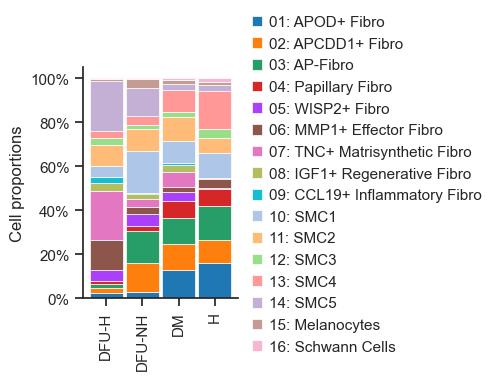

In [544]:
# -----------------------------------------------------------------------------
# Data Preparation & Plotting: NK Cell Proportions across Patients
# -----------------------------------------------------------------------------
# 1. Define specific sample batches (barlabels) to visualize.
# 2. Extract unique cell types from the 'anno-pca' annotation.
# 3. Construct 'age_df': A DataFrame where rows are samples and columns are cell types,
#    containing the raw counts of cells for each combination.
#
# Note on Labeling:, 'G13', 'G15', 'G17', 'G7', 'G8', 'G49', 'G42', 'G45'
 #            'G6', 'G11', 'G9', 'G35', 'G33', 'G34', 'G39',
  #           'G2A', 'G4A', 'G46', 'G48', 'G38', 'G41', 'G1A', 'G3A', 'G3', 'G5'
# To clearly distinguish patient samples from NK cell cluster IDs (e.g., NK1_0),
# we format the X-axis labels with a 'P' prefix (e.g., P01_0) in the final plot.
# -----------------------------------------------------------------------------
barlabels = ['DFU-H', 'DFU-NH', 'DM', 'H']
cell_types = list(adata_concat.obs['anno-Fib-number'].unique())
cell_types.sort()
age_df = pd.DataFrame(columns = list(cell_types))
for bar in barlabels:
    d1 = pd.DataFrame([len(adata_concat[(adata_concat.obs["anno-Fib-number"] == ct) & (adata_concat.obs["group"] == bar)]) for ct in list(cell_types)], index = list(cell_types), columns=[bar]).T
    age_df = pd.concat([age_df, d1])
fig0, ax0 = plt.subplots(figsize=(2, 3))
propPlot(age_df, ax=ax0, barlabels=barlabels)
ax0.set_xlabel('')
fig0.savefig(f"{figPath}/Fib_prop.pdf", bbox_inches='tight')

In [ ]:
from scipy.stats import fisher_exact, mannwhitneyu

def compare_cell_type_proportion(
    adata,
    target_label,
    anno_col='anno-Fib',
    treatment_col='group',
    batch_col='batch',
    pre_label='Pre',
    post_label='Post',
    plot=True,
    figsize=(5, 5),
    title_prefix=None
):
    """
    Compare the proportion of one or more cell types between pre- and post-treatment samples.
    
    Supports:
      - Single cell type (e.g., 'C08_Treg_FOXP3')
      - Multiple cell types combined (e.g., ['C08_Treg_FOXP3', 'C09_Treg_IL2RA'])
    
    Two statistical approaches:
      1. Cell-level Fisher's exact test (all cells)
      2. Sample-level one-sided Mann-Whitney U test (Post > Pre)

    Parameters:
    ----------
    adata : AnnData
        Single-cell data object with .obs metadata.
    target_label : str or list of str
        Cell type label(s) in anno_col to analyze. If list, proportions are summed.
    anno_col : str
        Column name for cell type annotation (default: 'anno').
    treatment_col : str
        Column name for treatment status (default: 'treatment').
    batch_col : str
        Column name for sample/batch ID (default: 'batch').
    pre_label : str
        Label for pre-treatment group (default: 'Pre').
    post_label : str
        Label for post-treatment group (default: 'Post').
    plot : bool
        Whether to generate a sample-level proportion plot (default: True).
    figsize : tuple
        Figure size (default: (5, 5)).
    title_prefix : str or None
        Custom title prefix. If None, auto-generated from target_label.

    Returns:
    -------
    dict : Dictionary with cell-level and sample-level results.
    """
    # === Normalize target_label to list ===
    if isinstance(target_label, str):
        target_labels = [target_label]
        label_display = target_label
    elif isinstance(target_label, (list, tuple)):
        target_labels = list(target_label)
        if len(target_labels) == 1:
            label_display = target_labels[0]
        else:
            label_display = f"{' + '.join(target_labels)} (combined)"
    else:
        raise ValueError("`target_label` must be a string or a list/tuple of strings.")
    
    # === Validate columns ===
    required_cols = [anno_col, treatment_col, batch_col]
    missing_cols = [col for col in required_cols if col not in adata.obs.columns]
    if missing_cols:
        raise ValueError(f"Missing required columns in adata.obs: {missing_cols}")
    
    df = adata.obs[required_cols].copy()
    df = df[df[treatment_col].isin([pre_label, post_label])].copy()
    
    if df.empty:
        raise ValueError("No samples found with the specified treatment labels.")
    
    # Identify cells belonging to any of the target types
    df['is_target'] = df[anno_col].isin(target_labels).astype(int)
    
    # === Step 1: Cell-level Fisher's exact test ===
    contingency = pd.crosstab(df[treatment_col], df['is_target'])
    for col in [0, 1]:
        if col not in contingency.columns:
            contingency[col] = 0
    contingency = contingency[[0, 1]]
    contingency.columns = ['Non-Target', 'Target']
    contingency.index.name = 'Treatment'

    odds_ratio, p_fisher = fisher_exact(contingency.values, alternative='two-sided')
    
    total_pre = contingency.loc[pre_label].sum()
    total_post = contingency.loc[post_label].sum()
    prop_pre_cell = contingency.loc[pre_label, 'Target'] / total_pre if total_pre > 0 else 0
    prop_post_cell = contingency.loc[post_label, 'Target'] / total_post if total_post > 0 else 0

    print("=== Cell-level Analysis (All Cells) ===")
    print(f"Target cell type(s): {label_display}")
    print(contingency)
    print(f"\nFisher's exact test p-value: {p_fisher:.3e}")
    print(f"Proportion - {pre_label}: {prop_pre_cell:.1%}, {post_label}: {prop_post_cell:.1%}\n")

    # === Step 2: Sample-level analysis ===
    summary_rows = []
    for batch_name, sub in df.groupby(batch_col):
        if len(sub) == 0:
            continue
        treatment_val = sub[treatment_col].iloc[0]
        if treatment_val not in [pre_label, post_label]:
            continue
        prop = sub['is_target'].mean()
        summary_rows.append({
            'batch': batch_name,
            'treatment': treatment_val,
            'prop_target': prop
        })
    
    if not summary_rows:
        raise ValueError("No valid batches found for sample-level analysis.")
    
    sample_df = pd.DataFrame(summary_rows)
    pre_props = sample_df[sample_df['treatment'] == pre_label]['prop_target'].values
    post_props = sample_df[sample_df['treatment'] == post_label]['prop_target'].values

    if len(pre_props) == 0 or len(post_props) == 0:
        raise ValueError("Missing Pre or Post group in sample-level data.")

    # One-sided Mann-Whitney U test (Post > Pre)
    u_stat, p_mwu_one_sided = mannwhitneyu(post_props, pre_props, alternative='greater')
    
    mean_pre = np.mean(pre_props)
    mean_post = np.mean(post_props)
    median_pre = np.median(pre_props)
    median_post = np.median(post_props)

    print("=== Sample-level Analysis (Per Sample) ===")
    print(f"Number of samples: {pre_label} = {len(pre_props)}, {post_label} = {len(post_props)}")
    print(f"Mean proportion - {pre_label}: {mean_pre:.1%}, {post_label}: {mean_post:.1%}")
    print(f"Median proportion - {pre_label}: {median_pre:.1%}, {post_label}: {median_post:.1%}")
    print(f"Mann-Whitney U test (one-sided, {post_label} > {pre_label}): p = {p_mwu_one_sided:.3f}\n")

    # === Step 3: Visualization ===
    if plot:
        title = title_prefix or label_display
        plt.figure(figsize=figsize)
        sns.stripplot(
            data=sample_df,
            x='treatment',
            y='prop_target',
            order=[pre_label, post_label],
            size=6,
            palette=['lightblue', 'salmon']
        )
        plt.ylabel('Proportion')
        plt.xlabel('Treatment Group')
        plt.title(title)
        plt.tight_layout()
        plt.show()

    return {
        'target_labels': target_labels,
        'cell_level': {
            'contingency_table': contingency,
            'p_fisher': p_fisher,
            'prop_pre': prop_pre_cell,
            'prop_post': prop_post_cell
        },
        'sample_level': {
            'n_pre': len(pre_props),
            'n_post': len(post_props),
            'mean_pre': mean_pre,
            'mean_post': mean_post,
            'median_pre': median_pre,
            'median_post': median_post,
            'p_mwu_one_sided': p_mwu_one_sided,
            'u_stat': u_stat,
            'pre_props': pre_props,
            'post_props': post_props
        },
        'summary_df': sample_df
    }

In [549]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statannotations.Annotator import Annotator

def plot_subset_proportion(
    results,
    selected_celltypes = None,
    figsize=(7, 4),
    box_colors=['lightblue', 'salmon'],
    dot_colors=['#4c72b0', '#dd8452'],
    box_width=0.7,
    dot_size=3,
    line_alpha=0.5,
    line_lw=1,
    xtick_rotation=90,
    ylabel='Proportion of Fibro (%)',
    title='',
    legend_title='Treatment',
    save_path=None
):
    """
    Plot paired boxplot + stripplot for fibroblast subset proportions across treatment groups.
    - Automatically draws lines for paired samples (same patient pre/post)
    - Adds significance asterisks
    - Formats y-axis as percentage
    - Allows selecting a subset of cell types for display

    Parameters
    ----------
    results : dict
        Input result dictionary containing summary_df and p-values for each cell type.
    selected_celltypes : list, optional
        List of cell type names to display (e.g., ['TNC+ Fibro', 'IGF1+ Fibro']).
        If None, all cell types in results are plotted.
    figsize : tuple
        Figure size (width, height).
    box_colors : list
        Color palette for boxplots.
    dot_colors : list
        Color palette for stripplot dots.
    box_width : float
        Width of boxplots.
    dot_size : float
        Size of scatter points.
    line_alpha : float
        Transparency of patient-paired connecting lines.
    line_lw : float
        Line width of paired connections.
    xtick_rotation : int
        Rotation angle for x-axis tick labels.
    legend_title : str
        Title for the legend.
    save_path : str, optional
        Path to save the figure (e.g., 'figure.pdf'). If None, figure is only displayed.

    Returns
    -------
    fig : matplotlib.figure.Figure
    ax : matplotlib.axes.Axes
    """
    # ---------------------- Data preparation ----------------------
    df = pd.DataFrame(columns=['batch', 'treatment', 'prop_target', 'celltype'])
    for key in results.keys():
        _df = results[key]['summary_df'].copy()
        _df['celltype'] = key
        _df.columns = ['batch', 'treatment', 'prop_target', 'celltype']
        df = pd.concat([df, _df], ignore_index=True)

    # Extract patient ID
    df['patient_id'] = df['batch'].str.extract(r'([A-Za-z0-9]+)_\d+')

    # ---------------------- Filter selected cell types 👈 ----------------------
    if selected_celltypes is not None:
        df = df[df['celltype'].isin(selected_celltypes)].copy()

    # ---------------------- Initialize plot ----------------------
    fig, ax = plt.subplots(1, 1, figsize=figsize)

    # Boxplot
    sns.boxplot(
        data=df,
        x='celltype',
        y='prop_target',
        hue='treatment',
        ax=ax,
        boxprops=dict(alpha=0.6),
        width=box_width,
        showfliers=False,
        palette=box_colors
    )

    # Stripplot
    sns.stripplot(
        data=df,
        x='celltype',
        y='prop_target',
        hue='treatment',
        ax=ax,
        palette=dot_colors,
        size=dot_size,
        alpha=0.8,
        dodge=True,
        jitter=True,
        zorder=2
    )

    # ---------------------- Paired patient lines ----------------------
    x_labels = [lbl.get_text() for lbl in ax.get_xticklabels()]
    for i, celltype in enumerate(x_labels):
        dots_pre = ax.collections[i * 2]
        dots_post = ax.collections[i * 2 + 1]
        pre_coords = dots_pre.get_offsets()
        post_coords = dots_post.get_offsets()

        cell_df = df[df['celltype'] == celltype]
        treat_groups = df['treatment'].unique()
        pre_df = cell_df[cell_df['treatment'] == treat_groups[0]].reset_index(drop=True)
        post_df = cell_df[cell_df['treatment'] == treat_groups[1]].reset_index(drop=True)

        for patient_id, group in cell_df.groupby('patient_id'):
            if len(group) == 2:
                try:
                    pre_idx = pre_df[pre_df['patient_id'] == patient_id].index[0]
                    post_idx = post_df[post_df['patient_id'] == patient_id].index[0]
                    x1, y1 = pre_coords[pre_idx]
                    x2, y2 = post_coords[post_idx]
                    ax.plot([x1, x2], [y1, y2],
                            color='gray', alpha=line_alpha, lw=line_lw, zorder=0)
                except Exception:
                    continue

    # ---------------------- Style formatting ----------------------
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))
    ax.set_xticklabels(ax.get_xticklabels(), rotation=xtick_rotation, fontsize=10, ha='right')
    ax.set_yticklabels(ax.get_yticklabels(), fontsize=10)
    ax.set_xlabel('')
    ax.set_ylabel(ylabel, fontsize=10)
    ax.set_title(title,y=1.25, fontsize=12)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    handles, labels = ax.get_legend_handles_labels()
    
    ax.legend(handles[:2], labels[:2],
              bbox_to_anchor=(1, 1), loc='upper left',
              borderpad=0.4,
              fontsize=10,
              columnspacing=1,
              title=legend_title, frameon=False)

    # ---------------------- Significance asterisks ----------------------
    def p_to_asterisk(pvalue):
        if pvalue <= 0.0001: return '****'
        elif pvalue <= 0.001: return '***'
        elif pvalue <= 0.01: return '**'
        elif pvalue <= 0.05: return '*'
        else: return 'ns'

    pairs = []
    annotations = []
    treat1, treat2 = df['treatment'].unique()

    # Only use selected cell types for significance
    plot_celltypes = selected_celltypes if selected_celltypes is not None else list(results.keys())
    for key in plot_celltypes:
        pairs.append(((key, treat1), (key, treat2)))
        p_val = results[key]['sample_level']['p_mwu_one_sided']
        annotations.append(p_to_asterisk(p_val))
        print(f'Significance for {key} ({treat1} vs. {treat2}): p={p_val}')

    annotator = Annotator(ax, pairs, data=df,
                          x='celltype', y='prop_target', hue='treatment')
    annotator.configure(test=None, loc='outside')
    annotator.annotate_custom_annotations(annotations)

    plt.tight_layout()
    if save_path is not None:
        plt.savefig(save_path, bbox_inches='tight')
    plt.show()

    return fig, ax

=== Cell-level Analysis (All Cells) ===
Target cell type(s): AP-Fibro
                Non-Target  Target
Treatment                         
Foot Skin            22392    1170
Forearm Biopsy        2729     485

Fisher's exact test p-value: 7.176e-86
Proportion - Forearm Biopsy: 15.1%, Foot Skin: 5.0%

=== Sample-level Analysis (Per Sample) ===
Number of samples: Forearm Biopsy = 5, Foot Skin = 14
Mean proportion - Forearm Biopsy: 12.4%, Foot Skin: 4.9%
Median proportion - Forearm Biopsy: 11.7%, Foot Skin: 0.3%
Mann-Whitney U test (one-sided, Foot Skin > Forearm Biopsy): p = 0.991

=== Cell-level Analysis (All Cells) ===
Target cell type(s): APCDD1+ Fibro
                Non-Target  Target
Treatment                         
Foot Skin            22487    1075
Forearm Biopsy        2736     478

Fisher's exact test p-value: 8.806e-93
Proportion - Forearm Biopsy: 14.9%, Foot Skin: 4.6%

=== Sample-level Analysis (Per Sample) ===
Number of samples: Forearm Biopsy = 5, Foot Skin = 14
Mean pr

/tmp/ipykernel_1296156/1644427008.py:105: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for batch_name, sub in df.groupby(batch_col):
/tmp/ipykernel_1296156/1644427008.py:105: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for batch_name, sub in df.groupby(batch_col):
/tmp/ipykernel_1296156/1644427008.py:105: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for batch_name, sub in df.groupby(batch_col):
/tmp/ipykernel_1296156

=== Sample-level Analysis (Per Sample) ===
Number of samples: Forearm Biopsy = 5, Foot Skin = 14
Mean proportion - Forearm Biopsy: 0.0%, Foot Skin: 23.1%
Median proportion - Forearm Biopsy: 0.0%, Foot Skin: 23.1%
Mann-Whitney U test (one-sided, Foot Skin > Forearm Biopsy): p = 0.001

=== Cell-level Analysis (All Cells) ===
Target cell type(s): Schwann Cells
                Non-Target  Target
Treatment                         
Foot Skin            23533      29
Forearm Biopsy        3158      56

Fisher's exact test p-value: 2.257e-31
Proportion - Forearm Biopsy: 1.7%, Foot Skin: 0.1%

=== Sample-level Analysis (Per Sample) ===
Number of samples: Forearm Biopsy = 5, Foot Skin = 14
Mean proportion - Forearm Biopsy: 1.5%, Foot Skin: 0.2%
Median proportion - Forearm Biopsy: 1.3%, Foot Skin: 0.1%
Mann-Whitney U test (one-sided, Foot Skin > Forearm Biopsy): p = 0.979

=== Cell-level Analysis (All Cells) ===
Target cell type(s): TNC+ Matrisynthetic Fibro
                Non-Target  Target
Tre

/tmp/ipykernel_1296156/1644427008.py:105: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for batch_name, sub in df.groupby(batch_col):
/tmp/ipykernel_1296156/1644427008.py:105: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for batch_name, sub in df.groupby(batch_col):
/tmp/ipykernel_1296156/1644427008.py:105: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for batch_name, sub in df.groupby(batch_col):
/tmp/ipykernel_1296156

CCL19+ Inflammatory Fibro_Foot Skin vs. CCL19+ Inflammatory Fibro_Forearm Biopsy: **
MMP1+ Effector Fibro_Foot Skin vs. MMP1+ Effector Fibro_Forearm Biopsy: **
TNC+ Matrisynthetic Fibro_Foot Skin vs. TNC+ Matrisynthetic Fibro_Forearm Biopsy: ***


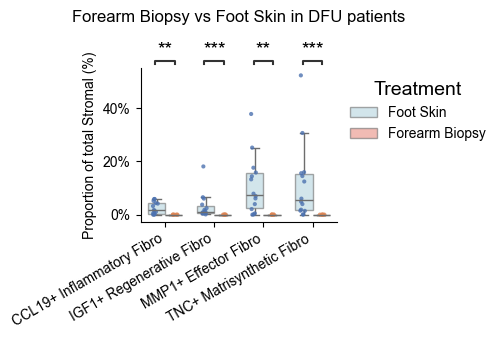

In [451]:
adata_Foot = adata_concat[adata_concat.obs['group'].isin(['DFU-NH', 'DFU-H'])]
adata_Foot = adata_Foot[adata_Foot.obs['tissue'].isin(['Forearm Biopsy', 'Foot Skin'])]
results = {}
results_keys = list(adata_concat.obs['anno-Fib'].cat.categories)
for key in results_keys:
    results[key] = compare_cell_type_proportion(adata_Foot, key, 'anno-Fib',treatment_col='tissue', pre_label='Forearm Biopsy', post_label='Foot Skin',plot=False)
fig, ax = plot_subset_proportion(results, figsize=(5,4), xtick_rotation=30, ylabel='Proportion of total Stromal (%)', title='Forearm Biopsy vs Foot Skin in DFU patients',
                                 selected_celltypes=['CCL19+ Inflammatory Fibro',
       'IGF1+ Regenerative Fibro', 'MMP1+ Effector Fibro','TNC+ Matrisynthetic Fibro'])
fig.savefig(f"{figPath}/Forearm Biopsy vs Foot Skin in DFU patients.pdf", bbox_inches='tight')

=== Cell-level Analysis (All Cells) ===
Target cell type(s): AP-Fibro
           Non-Target  Target
Treatment                    
DFU-H           15800      76
DFU-NH           6592    1094

Fisher's exact test p-value: 0.000e+00
Proportion - DFU-NH: 14.2%, DFU-H: 0.5%

=== Sample-level Analysis (Per Sample) ===
Number of samples: DFU-NH = 5, DFU-H = 9
Mean proportion - DFU-NH: 12.7%, DFU-H: 0.6%
Median proportion - DFU-NH: 3.1%, DFU-H: 0.2%
Mann-Whitney U test (one-sided, DFU-H > DFU-NH): p = 0.862

=== Cell-level Analysis (All Cells) ===
Target cell type(s): APCDD1+ Fibro
           Non-Target  Target
Treatment                    
DFU-H           15679     197
DFU-NH           6808     878

Fisher's exact test p-value: 4.104e-253
Proportion - DFU-NH: 11.4%, DFU-H: 1.2%

=== Sample-level Analysis (Per Sample) ===
Number of samples: DFU-NH = 5, DFU-H = 9
Mean proportion - DFU-NH: 9.7%, DFU-H: 1.4%
Median proportion - DFU-NH: 1.9%, DFU-H: 0.3%
Mann-Whitney U test (one-sided, DFU-H > DFU

/tmp/ipykernel_1296156/1644427008.py:105: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for batch_name, sub in df.groupby(batch_col):
/tmp/ipykernel_1296156/1644427008.py:105: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for batch_name, sub in df.groupby(batch_col):
/tmp/ipykernel_1296156/1644427008.py:105: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for batch_name, sub in df.groupby(batch_col):
/tmp/ipykernel_1296156

=== Sample-level Analysis (Per Sample) ===
Number of samples: DFU-NH = 5, DFU-H = 9
Mean proportion - DFU-NH: 19.6%, DFU-H: 25.0%
Median proportion - DFU-NH: 18.7%, DFU-H: 27.8%
Mann-Whitney U test (one-sided, DFU-H > DFU-NH): p = 0.182

=== Cell-level Analysis (All Cells) ===
Target cell type(s): Schwann Cells
           Non-Target  Target
Treatment                    
DFU-H           15862      14
DFU-NH           7671      15

Fisher's exact test p-value: 4.498e-02
Proportion - DFU-NH: 0.2%, DFU-H: 0.1%

=== Sample-level Analysis (Per Sample) ===
Number of samples: DFU-NH = 5, DFU-H = 9
Mean proportion - DFU-NH: 0.2%, DFU-H: 0.1%
Median proportion - DFU-NH: 0.2%, DFU-H: 0.1%
Mann-Whitney U test (one-sided, DFU-H > DFU-NH): p = 0.741

=== Cell-level Analysis (All Cells) ===
Target cell type(s): TNC+ Matrisynthetic Fibro
           Non-Target  Target
Treatment                    
DFU-H           11849    4027
DFU-NH           7343     343

Fisher's exact test p-value: 0.000e+00
Propor

/tmp/ipykernel_1296156/1644427008.py:105: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for batch_name, sub in df.groupby(batch_col):
/tmp/ipykernel_1296156/1644427008.py:105: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for batch_name, sub in df.groupby(batch_col):
/tmp/ipykernel_1296156/1644427008.py:105: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for batch_name, sub in df.groupby(batch_col):
/tmp/ipykernel_1296156

CCL19+ Inflammatory Fibro_DFU-H vs. CCL19+ Inflammatory Fibro_DFU-NH: ns
MMP1+ Effector Fibro_DFU-H vs. MMP1+ Effector Fibro_DFU-NH: *
TNC+ Matrisynthetic Fibro_DFU-H vs. TNC+ Matrisynthetic Fibro_DFU-NH: **


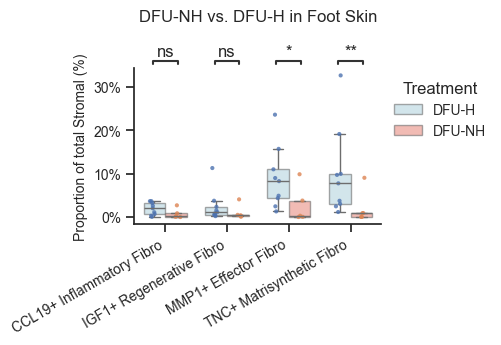

In [550]:
adata_Foot = adata_concat[adata_concat.obs['group'].isin(['DFU-NH', 'DFU-H'])]
adata_Foot = adata_Foot[adata_Foot.obs['tissue'].isin(['Foot Skin'])]
results = {}
results_keys = list(adata_concat.obs['anno-Fib'].cat.categories)
for key in results_keys:
    results[key] = compare_cell_type_proportion(adata_Foot, key, 'anno-Fib',treatment_col='group', pre_label='DFU-NH', post_label='DFU-H',plot=False)
fig, ax = plot_subset_proportion(results, figsize=(5,4), xtick_rotation=30, ylabel='Proportion of total Stromal (%)', title='DFU-NH vs. DFU-H in Foot Skin',
                                 selected_celltypes=['CCL19+ Inflammatory Fibro',
       'IGF1+ Regenerative Fibro', 'MMP1+ Effector Fibro','TNC+ Matrisynthetic Fibro'])
fig.savefig(f"{figPath}/DFU-NH vs DFU-H in Foot Skin.pdf", bbox_inches='tight')

=== Cell-level Analysis (All Cells) ===
Target cell type(s): AP-Fibro
           Non-Target  Target
Treatment                    
DFU              2729     485
H                5667    1466

Fisher's exact test p-value: 2.688e-11
Proportion - H: 20.6%, DFU: 15.1%

=== Sample-level Analysis (Per Sample) ===
Number of samples: H = 4, DFU = 5
Mean proportion - H: 21.0%, DFU: 12.4%
Median proportion - H: 19.5%, DFU: 11.7%
Mann-Whitney U test (one-sided, DFU > H): p = 0.968

=== Cell-level Analysis (All Cells) ===
Target cell type(s): APCDD1+ Fibro
           Non-Target  Target
Treatment                    
DFU              2736     478
H                6391     742

Fisher's exact test p-value: 1.501e-10
Proportion - H: 10.4%, DFU: 14.9%

=== Sample-level Analysis (Per Sample) ===
Number of samples: H = 4, DFU = 5
Mean proportion - H: 10.3%, DFU: 14.2%
Median proportion - H: 9.6%, DFU: 13.5%
Mann-Whitney U test (one-sided, DFU > H): p = 0.365

=== Cell-level Analysis (All Cells) ===
Target

/tmp/ipykernel_1296156/1644427008.py:105: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for batch_name, sub in df.groupby(batch_col):
/tmp/ipykernel_1296156/1644427008.py:105: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for batch_name, sub in df.groupby(batch_col):
/tmp/ipykernel_1296156/1644427008.py:105: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for batch_name, sub in df.groupby(batch_col):
/tmp/ipykernel_1296156

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

SMC2_H vs. SMC2_DFU: ns
SMC3_H vs. SMC3_DFU: ns
SMC4_H vs. SMC4_DFU: ns
SMC5_H vs. SMC5_DFU: ns
Schwann Cells_H vs. Schwann Cells_DFU: ns
TNC+ Matrisynthetic Fibro_H vs. TNC+ Matrisynthetic Fibro_DFU: ns
WISP2+ Fibro_H vs. WISP2+ Fibro_DFU: ns
SMC1_H vs. SMC1_DFU: ns
APCDD1+ Fibro_H vs. APCDD1+ Fibro_DFU: ns
AP-Fibro_H vs. AP-Fibro_DFU: ns
APOD+ Fibro_H vs. APOD+ Fibro_DFU: ns
CCL19+ Inflammatory Fibro_H vs. CCL19+ Inflammatory Fibro_DFU: ns
IGF1+ Regenerative Fibro_H vs. IGF1+ Regenerative Fibro_DFU: ns
MMP1+ Effector Fibro_H vs. MMP1+ Effector Fibro_DFU: ns
Melanocytes_H vs. Melanocytes_DFU: *
Papillary Fibro_H vs. Papillary Fibro_DFU: ns


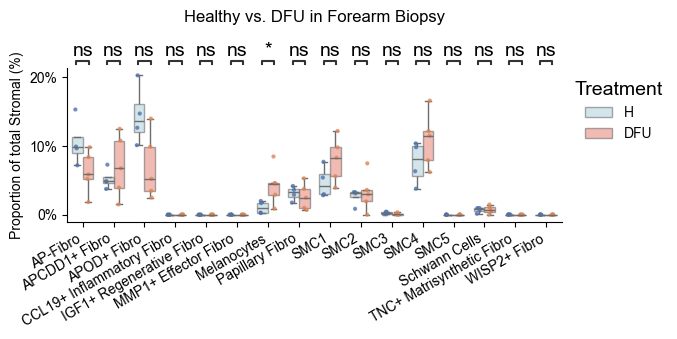

In [463]:
annot = {
    'H': ['H'],
    'DM': ['DM'],
    'DFU': ['DFU-NH', 'DFU-H'],
}
adata_concat = anno(adata_concat, annot, 'total_group', 'group')
adata_Foot = adata_concat[adata_concat.obs['total_group'].isin(['H', 'DFU'])]
adata_Foot = adata_Foot[adata_Foot.obs['tissue'].isin(['Forearm Biopsy'])]
results = {}
results_keys = list(adata_concat.obs['anno-Fib'].cat.categories)
for key in results_keys:
    results[key] = compare_cell_type_proportion(adata_Foot, key, 'anno-Fib',treatment_col='total_group', pre_label='H', post_label='DFU',plot=False)
fig, ax = plot_subset_proportion(results, figsize=(7,4),xtick_rotation=30, ylabel='Proportion of total Stromal (%)', title='Healthy vs. DFU in Forearm Biopsy')
fig.savefig(f"{figPath}/Healthy vs. DFU in Forearm Biopsy.pdf", bbox_inches='tight')

=== Cell-level Analysis (All Cells) ===
Target cell type(s): AP-Fibro
                Non-Target  Target
Treatment                         
Foot Skin            22392    1170
Forearm Biopsy        2729     485

Fisher's exact test p-value: 7.176e-86
Proportion - Forearm Biopsy: 15.1%, Foot Skin: 5.0%

=== Sample-level Analysis (Per Sample) ===
Number of samples: Forearm Biopsy = 5, Foot Skin = 14
Mean proportion - Forearm Biopsy: 12.4%, Foot Skin: 4.9%
Median proportion - Forearm Biopsy: 11.7%, Foot Skin: 0.3%
Mann-Whitney U test (one-sided, Foot Skin > Forearm Biopsy): p = 0.991

=== Cell-level Analysis (All Cells) ===
Target cell type(s): APCDD1+ Fibro
                Non-Target  Target
Treatment                         
Foot Skin            22487    1075
Forearm Biopsy        2736     478

Fisher's exact test p-value: 8.806e-93
Proportion - Forearm Biopsy: 14.9%, Foot Skin: 4.6%

=== Sample-level Analysis (Per Sample) ===
Number of samples: Forearm Biopsy = 5, Foot Skin = 14
Mean pr

/tmp/ipykernel_1296156/1644427008.py:105: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for batch_name, sub in df.groupby(batch_col):
/tmp/ipykernel_1296156/1644427008.py:105: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for batch_name, sub in df.groupby(batch_col):
/tmp/ipykernel_1296156/1644427008.py:105: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for batch_name, sub in df.groupby(batch_col):
/tmp/ipykernel_1296156

=== Sample-level Analysis (Per Sample) ===
Number of samples: Forearm Biopsy = 5, Foot Skin = 14
Mean proportion - Forearm Biopsy: 0.0%, Foot Skin: 23.1%
Median proportion - Forearm Biopsy: 0.0%, Foot Skin: 23.1%
Mann-Whitney U test (one-sided, Foot Skin > Forearm Biopsy): p = 0.001

=== Cell-level Analysis (All Cells) ===
Target cell type(s): Schwann Cells
                Non-Target  Target
Treatment                         
Foot Skin            23533      29
Forearm Biopsy        3158      56

Fisher's exact test p-value: 2.257e-31
Proportion - Forearm Biopsy: 1.7%, Foot Skin: 0.1%

=== Sample-level Analysis (Per Sample) ===
Number of samples: Forearm Biopsy = 5, Foot Skin = 14
Mean proportion - Forearm Biopsy: 1.5%, Foot Skin: 0.2%
Median proportion - Forearm Biopsy: 1.3%, Foot Skin: 0.1%
Mann-Whitney U test (one-sided, Foot Skin > Forearm Biopsy): p = 0.979

=== Cell-level Analysis (All Cells) ===
Target cell type(s): TNC+ Matrisynthetic Fibro
                Non-Target  Target
Tre

/tmp/ipykernel_1296156/1644427008.py:105: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for batch_name, sub in df.groupby(batch_col):
/tmp/ipykernel_1296156/1644427008.py:105: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for batch_name, sub in df.groupby(batch_col):
/tmp/ipykernel_1296156/1644427008.py:105: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for batch_name, sub in df.groupby(batch_col):
/tmp/ipykernel_1296156

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

SMC2_Foot Skin vs. SMC2_Forearm Biopsy: ns
SMC3_Foot Skin vs. SMC3_Forearm Biopsy: **
SMC4_Foot Skin vs. SMC4_Forearm Biopsy: ns
SMC5_Foot Skin vs. SMC5_Forearm Biopsy: ***
Schwann Cells_Foot Skin vs. Schwann Cells_Forearm Biopsy: ns
TNC+ Matrisynthetic Fibro_Foot Skin vs. TNC+ Matrisynthetic Fibro_Forearm Biopsy: ***
WISP2+ Fibro_Foot Skin vs. WISP2+ Fibro_Forearm Biopsy: *
SMC1_Foot Skin vs. SMC1_Forearm Biopsy: ns
APCDD1+ Fibro_Foot Skin vs. APCDD1+ Fibro_Forearm Biopsy: ns
AP-Fibro_Foot Skin vs. AP-Fibro_Forearm Biopsy: ns
APOD+ Fibro_Foot Skin vs. APOD+ Fibro_Forearm Biopsy: ns
CCL19+ Inflammatory Fibro_Foot Skin vs. CCL19+ Inflammatory Fibro_Forearm Biopsy: **
IGF1+ Regenerative Fibro_Foot Skin vs. IGF1+ Regenerative Fibro_Forearm Biopsy: ***
MMP1+ Effector Fibro_Foot Skin vs. MMP1+ Effector

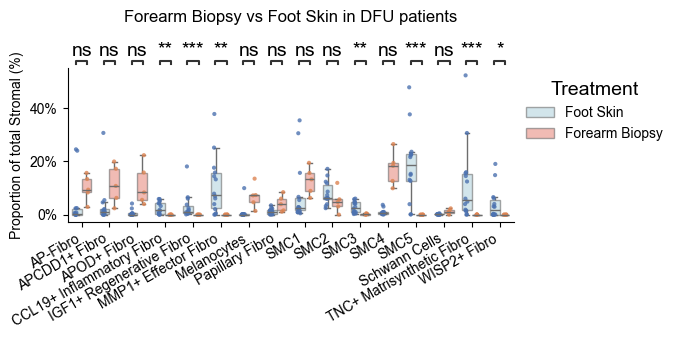

In [469]:
adata_Foot = adata_concat[adata_concat.obs['group'].isin(['DFU-NH', 'DFU-H'])]
adata_Foot = adata_Foot[adata_Foot.obs['tissue'].isin(['Forearm Biopsy', 'Foot Skin'])]
results = {}
results_keys = list(adata_concat.obs['anno-Fib'].cat.categories)
for key in results_keys:
    results[key] = compare_cell_type_proportion(adata_Foot, key, 'anno-Fib',treatment_col='tissue', pre_label='Forearm Biopsy', post_label='Foot Skin',plot=False)
fig, ax = plot_subset_proportion(results, figsize=(7,4), xtick_rotation=30, ylabel='Proportion of total Stromal (%)', title='Forearm Biopsy vs Foot Skin in DFU patients')
fig.savefig(f"{figPath}/Forearm Biopsy vs Foot Skin in DFU patients (all).pdf", bbox_inches='tight')

=== Cell-level Analysis (All Cells) ===
Target cell type(s): AP-Fibro
           Non-Target  Target
Treatment                    
DFU              2729     485
H                5667    1466

Fisher's exact test p-value: 2.688e-11
Proportion - H: 20.6%, DFU: 15.1%

=== Sample-level Analysis (Per Sample) ===
Number of samples: H = 4, DFU = 5
Mean proportion - H: 21.0%, DFU: 12.4%
Median proportion - H: 19.5%, DFU: 11.7%
Mann-Whitney U test (one-sided, DFU > H): p = 0.968

=== Cell-level Analysis (All Cells) ===
Target cell type(s): APCDD1+ Fibro
           Non-Target  Target
Treatment                    
DFU              2736     478
H                6391     742

Fisher's exact test p-value: 1.501e-10
Proportion - H: 10.4%, DFU: 14.9%

=== Sample-level Analysis (Per Sample) ===
Number of samples: H = 4, DFU = 5
Mean proportion - H: 10.3%, DFU: 14.2%
Median proportion - H: 9.6%, DFU: 13.5%
Mann-Whitney U test (one-sided, DFU > H): p = 0.365

=== Cell-level Analysis (All Cells) ===
Target

/tmp/ipykernel_1296156/1644427008.py:105: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for batch_name, sub in df.groupby(batch_col):
/tmp/ipykernel_1296156/1644427008.py:105: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for batch_name, sub in df.groupby(batch_col):
/tmp/ipykernel_1296156/1644427008.py:105: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for batch_name, sub in df.groupby(batch_col):
/tmp/ipykernel_1296156

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

SMC2_H vs. SMC2_DFU: ns
SMC3_H vs. SMC3_DFU: ns
SMC4_H vs. SMC4_DFU: ns
SMC5_H vs. SMC5_DFU: ns
Schwann Cells_H vs. Schwann Cells_DFU: ns
TNC+ Matrisynthetic Fibro_H vs. TNC+ Matrisynthetic Fibro_DFU: ns
WISP2+ Fibro_H vs. WISP2+ Fibro_DFU: ns
SMC1_H vs. SMC1_DFU: ns
APCDD1+ Fibro_H vs. APCDD1+ Fibro_DFU: ns
AP-Fibro_H vs. AP-Fibro_DFU: ns
APOD+ Fibro_H vs. APOD+ Fibro_DFU: ns
CCL19+ Inflammatory Fibro_H vs. CCL19+ Inflammatory Fibro_DFU: ns
IGF1+ Regenerative Fibro_H vs. IGF1+ Regenerative Fibro_DFU: ns
MMP1+ Effector Fibro_H vs. MMP1+ Effector Fibro_DFU: ns
Melanocytes_H vs. Melanocytes_DFU: *
Papillary Fibro_H vs. Papillary Fibro_DFU: ns


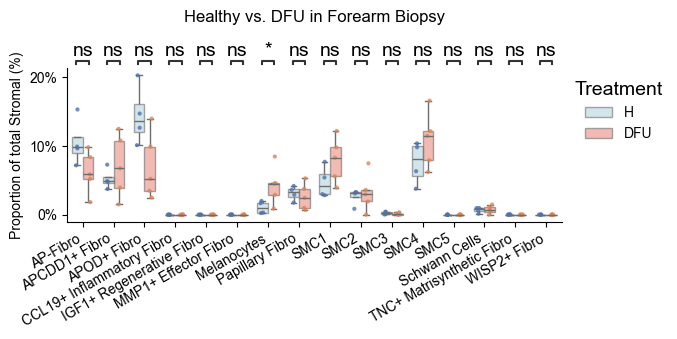

In [467]:
annot = {
    'H': ['H'],
    'DM': ['DM'],
    'DFU': ['DFU-NH', 'DFU-H'],
}
adata_concat = anno(adata_concat, annot, 'total_group', 'group')
adata_Foot = adata_concat[adata_concat.obs['total_group'].isin(['H', 'DFU'])]
adata_Foot = adata_Foot[adata_Foot.obs['tissue'].isin(['Forearm Biopsy'])]
results = {}
results_keys = list(adata_concat.obs['anno-Fib'].cat.categories)
for key in results_keys:
    results[key] = compare_cell_type_proportion(adata_Foot, key, 'anno-Fib',treatment_col='total_group', pre_label='H', post_label='DFU',plot=False)
fig, ax = plot_subset_proportion(results, figsize=(7,4),xtick_rotation=30, ylabel='Proportion of total Stromal (%)', title='Healthy vs. DFU in Forearm Biopsy')
fig.savefig(f"{figPath}/Healthy vs. DFU in Forearm Biopsy.pdf", bbox_inches='tight')

In [25]:
import gseapy as gp
from gseapy import Msigdb

def prep_enrichr(adata, groupby):
  """
  Prepares differential expression results for enrichment analysis.
  
  This function performs differential expression analysis using Scanpy's 
  rank_genes_groups method and organizes the results into a structured 
  DataFrame. It extracts gene names, scores, p-values, and log fold changes 
  for all groups, formatting them for downstream enrichment analysis.
  
  Parameters:
  -----------
  adata : AnnData
      The annotated AnnData object containing the single-cell data.
  groupby : str
      The key in adata.obs that defines the groups for comparison.
      
  Returns:
  --------
  pandas.DataFrame
      A DataFrame containing differential expression results with columns 
      formatted as 'group_key' (e.g., 'cluster_names', 'cluster_pvals').
  """
  # de analysis
  sc.tl.rank_genes_groups(adata, groupby=groupby)
  sc.tl.dendrogram(adata, groupby=groupby)
  # get deg result
  result = adata.uns['rank_genes_groups']
  groups = result['names'].dtype.names
  degs = pd.DataFrame(
      {group + '_' + key: result[key][group]
      for group in groups for key in ['names','scores', 'pvals','pvals_adj','logfoldchanges']})
  return degs

def run_enrichr_genelist(genelist):
  """
  Performs enrichment analysis on a list of genes using multiple databases.
  
  This function runs enrichment analysis on the provided gene list using 
  five different gene set libraries: KEGG pathways, GO Cellular Component, 
  MSigDB Hallmark, GO Molecular Function, and GO Biological Process. It 
  returns the results from all five analyses for comprehensive functional 
  annotation.
  
  Parameters:
  -----------
  genelist : list
      A list of gene symbols to be analyzed for enrichment.
      
  Returns:
  --------
  tuple
      A tuple containing five enrichment result objects (KEGG, Cellular 
      Component, Hallmark, Molecular Function, Biological Process).
  """
  kegg = gp.enrichr(genelist,
                  gene_sets='KEGG_2021_Human',
                  outdir=None)
  cc = gp.enrichr(genelist,
                      gene_sets='GO_Cellular_Component_2023',
                      outdir=None)
  hm = gp.enrichr(genelist,
                      gene_sets=['MSigDB_Hallmark_2020'],
                      outdir=None)
  mf = gp.enrichr(genelist,
                      gene_sets='GO_Molecular_Function_2023',
                      outdir=None)
  bp = gp.enrichr(genelist,
                      gene_sets=['GO_Biological_Process_2023'],
                      outdir=None)
  return kegg, cc, hm, mf, bp

def run_enrichr_scanpy(degs, group,direction='up', top_term=15, all_term=False, plot=True):
  """
  Performs enrichment analysis on Scanpy differential expression results.
  
  This function filters differentially expressed genes based on adjusted 
  p-value and log fold change, then performs enrichment analysis on either 
  up-regulated or down-regulated genes. It combines results from multiple 
  databases and optionally generates a bar plot of the top enriched terms.
  
  Parameters:
  -----------
  degs : pandas.DataFrame
      DataFrame containing differential expression results from prep_enrichr.
  group : str
      The group name to analyze (e.g., 'cluster_0').
  direction : str, optional
      Either 'up' or 'down' to specify direction of regulation.
  top_term : int, optional
      Number of top enriched terms to display in the plot.
  all_term : bool, optional
      If True, returns all enriched terms instead of just the top ones.
  plot : bool, optional
      If True, generates a bar plot of enriched terms.
      
  Returns:
  --------
  tuple
      A tuple containing the enrichment results DataFrame and the plot axis 
      (or None if plot=False).
  """
  # subset up or down regulated genes
  degs_sig = degs[degs[f'{group}_pvals_adj'] < 0.05]
  degs_up = degs_sig[degs_sig[f'{group}_logfoldchanges'] > 0]
  degs_dw = degs_sig[degs_sig[f'{group}_logfoldchanges'] < 0]
  degs_used = degs_up[f'{group}_names'] if direction == 'up' else degs_dw[f'{group}_names']
  kegg, cc, hm, mf, bp = run_enrichr_genelist(degs_used)
  go_res = pd.concat([kegg.res2d.head(top_term),
                    hm.res2d.head(top_term), 
                    cc.res2d.head(top_term), 
                    bp.res2d.head(top_term), 
                    mf.res2d.head(top_term)])
  if plot:
    ax = gp.barplot(go_res, figsize=(6,20),
                group ='Gene_set',
                top_term=top_term,
                color = ['#8b9cc4', '#f08961', '#62bb9f', '#e71f19', '#3d5eaa'],
                title ="The Most Enriched Terms")
  else:
    ax = None
  if all_term:
    go_res = pd.concat([kegg.res2d, hm.res2d, cc.res2d, bp.res2d, mf.res2d])
  return go_res, ax

In [26]:
adata_concat.obs['anno-Fib-number'].cat.categories

Index(['01: APOD+ Fibro', '02: APCDD1+ Fibro', '03: AP-Fibro',
       '04: Papillary Fibro', '05: WISP2+ Fibro', '06: MMP1+ Effector Fibro',
       '07: TNC+ Matrisynthetic Fibro', '08: IGF1+ Regenerative Fibro',
       '09: CCL19+ Inflammatory Fibro', '10: SMC1', '11: SMC2', '12: SMC3',
       '13: SMC4', '14: SMC5', '15: Melanocytes', '16: Schwann Cells'],
      dtype='object')

/home/rzh/miniconda3/lib/python3.11/site-packages/gseapy/plot.py:753: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda _x: _x.sort_values(by=self.colname).tail(self.n_terms))
/home/rzh/miniconda3/lib/python3.11/site-packages/gseapy/plot.py:753: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda _x: _x.sort_values(by=self.colname).tail(self.n_terms))
/home/rzh/miniconda3/lib/python3.11/site-package

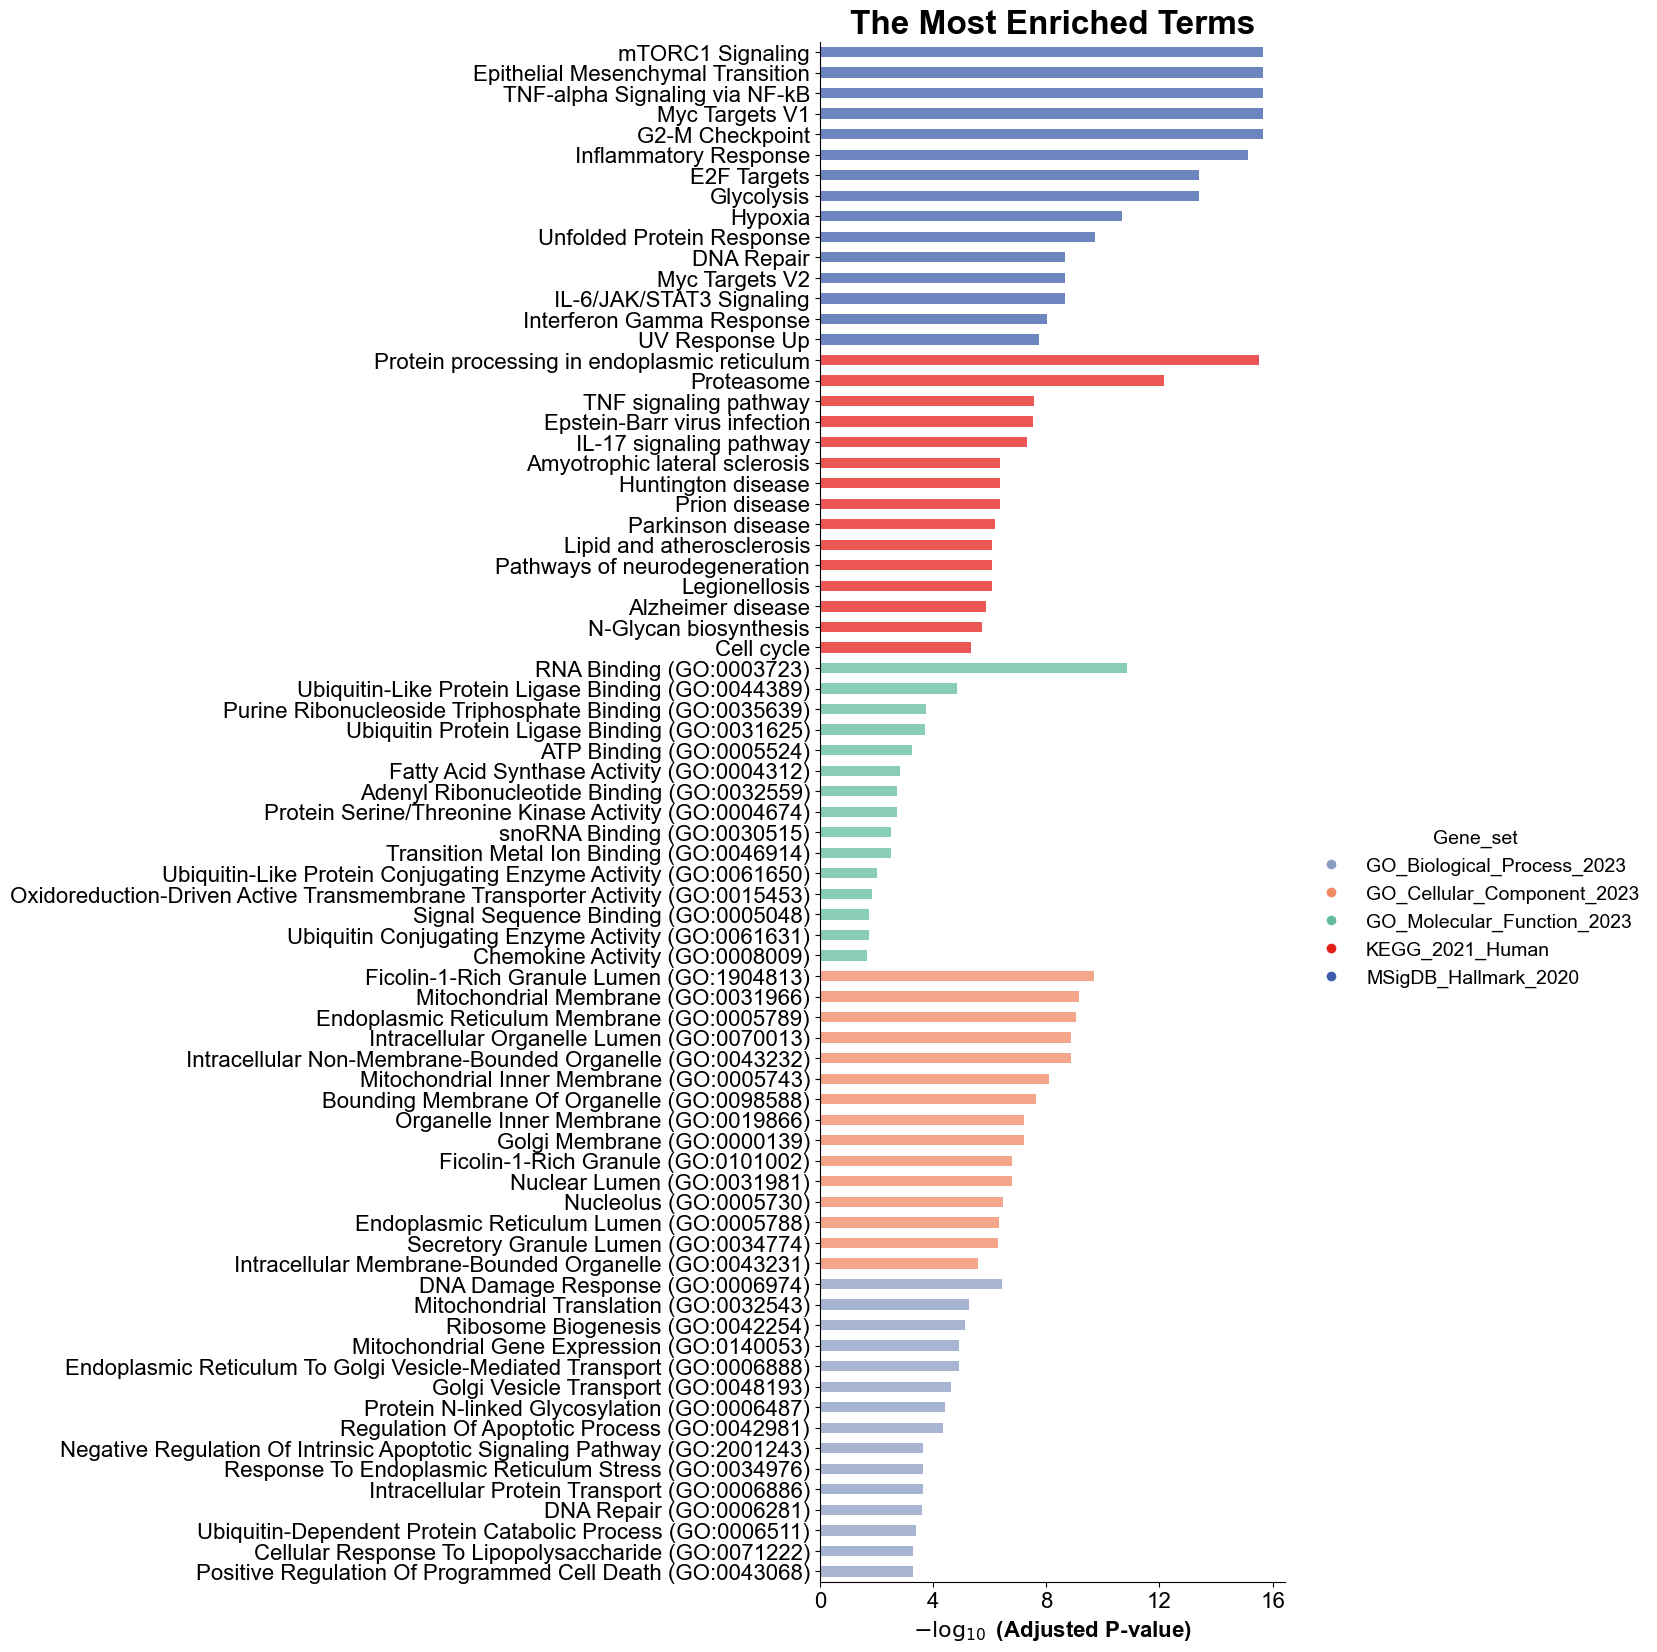

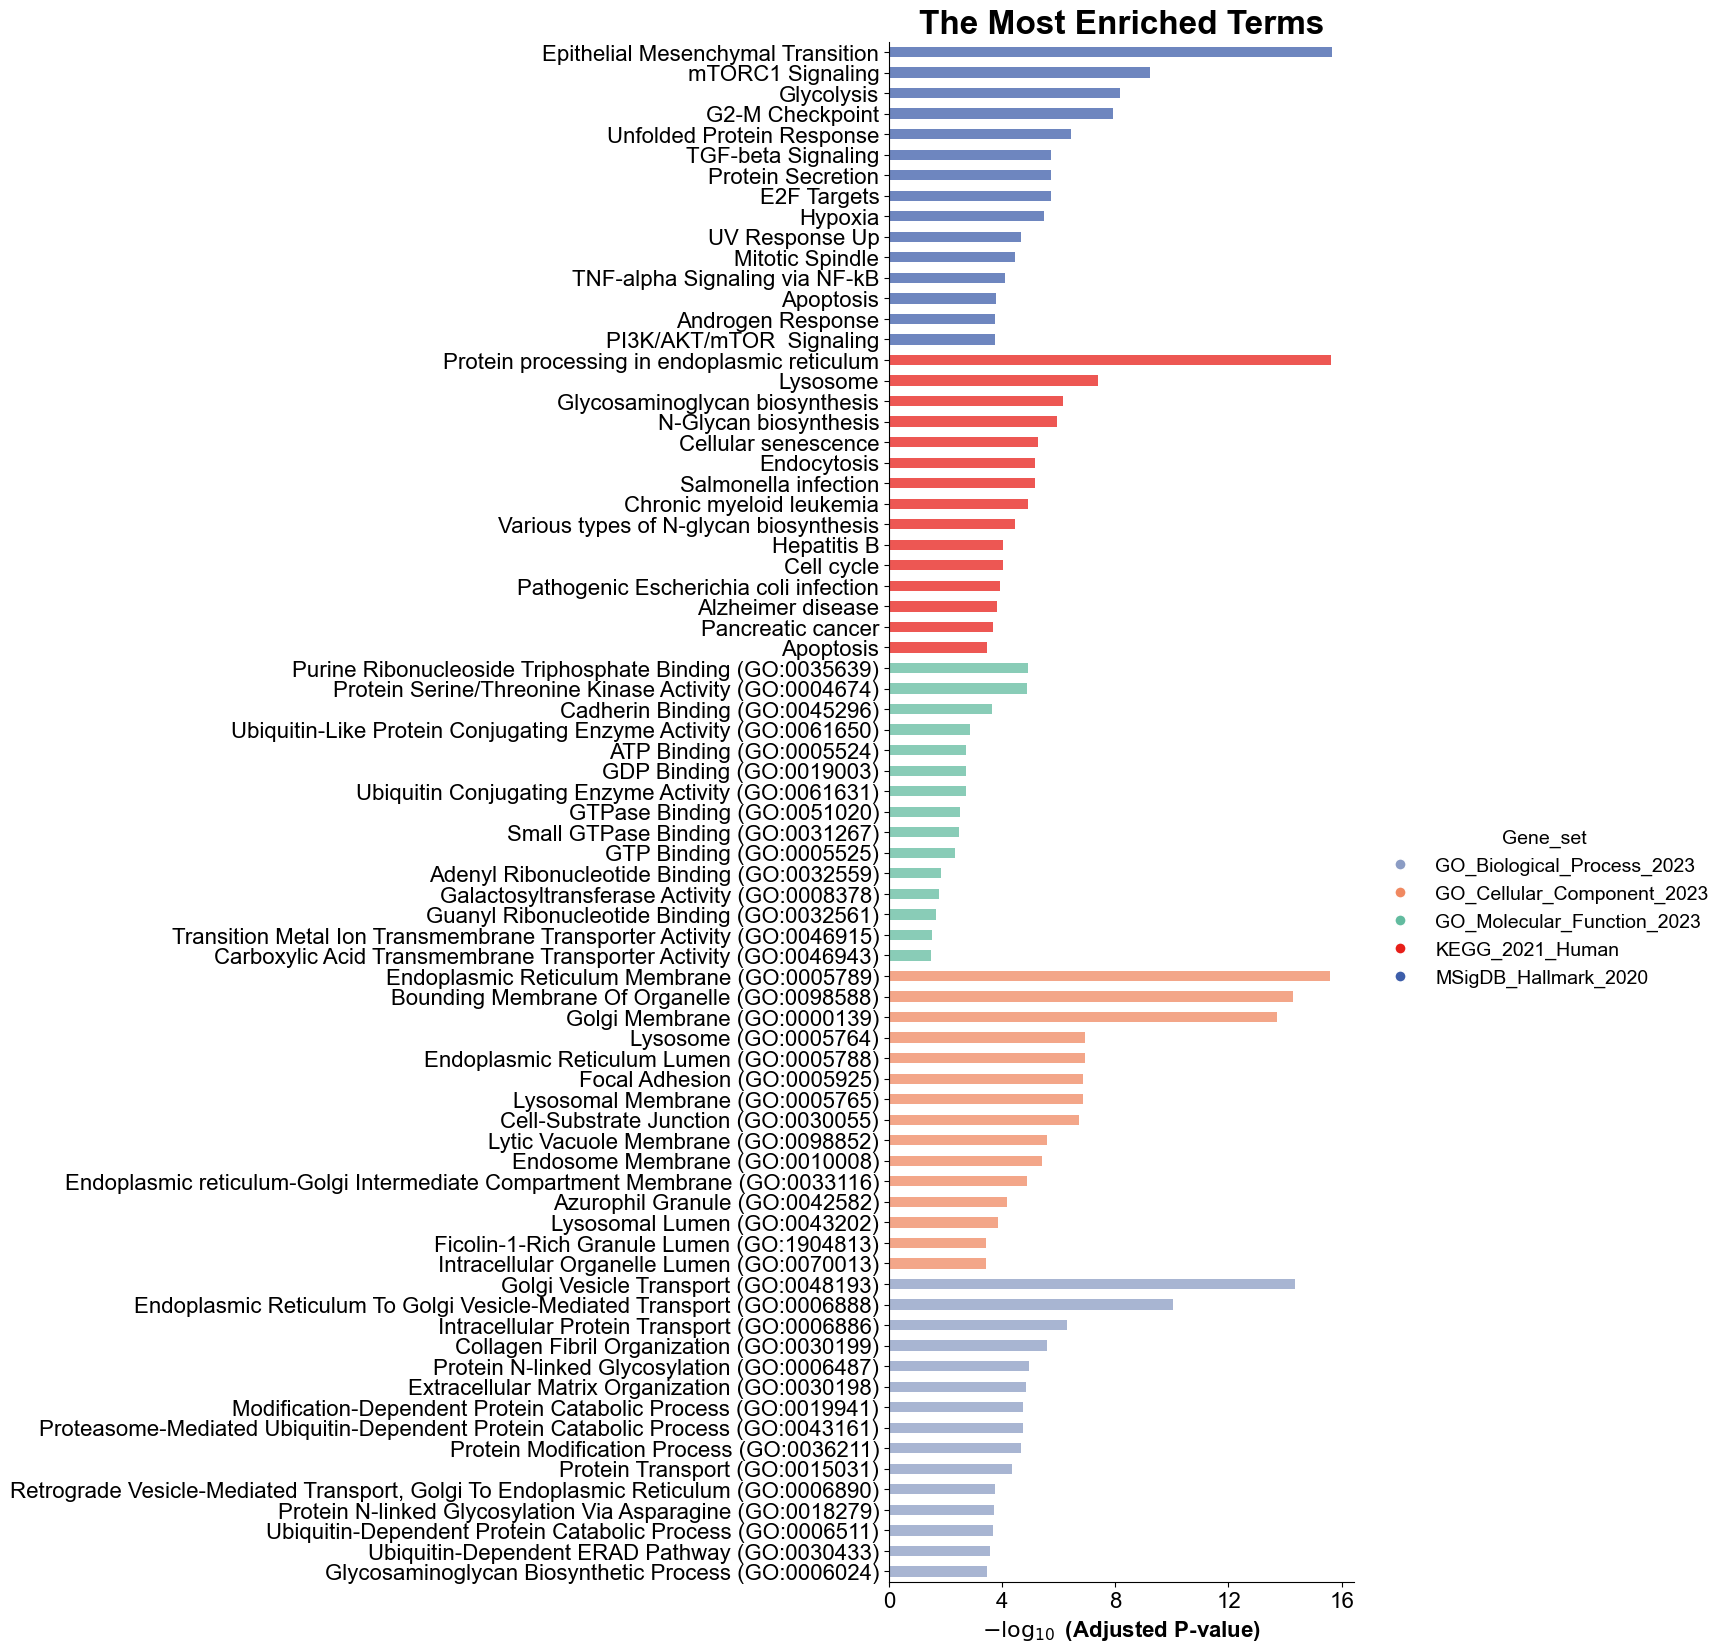

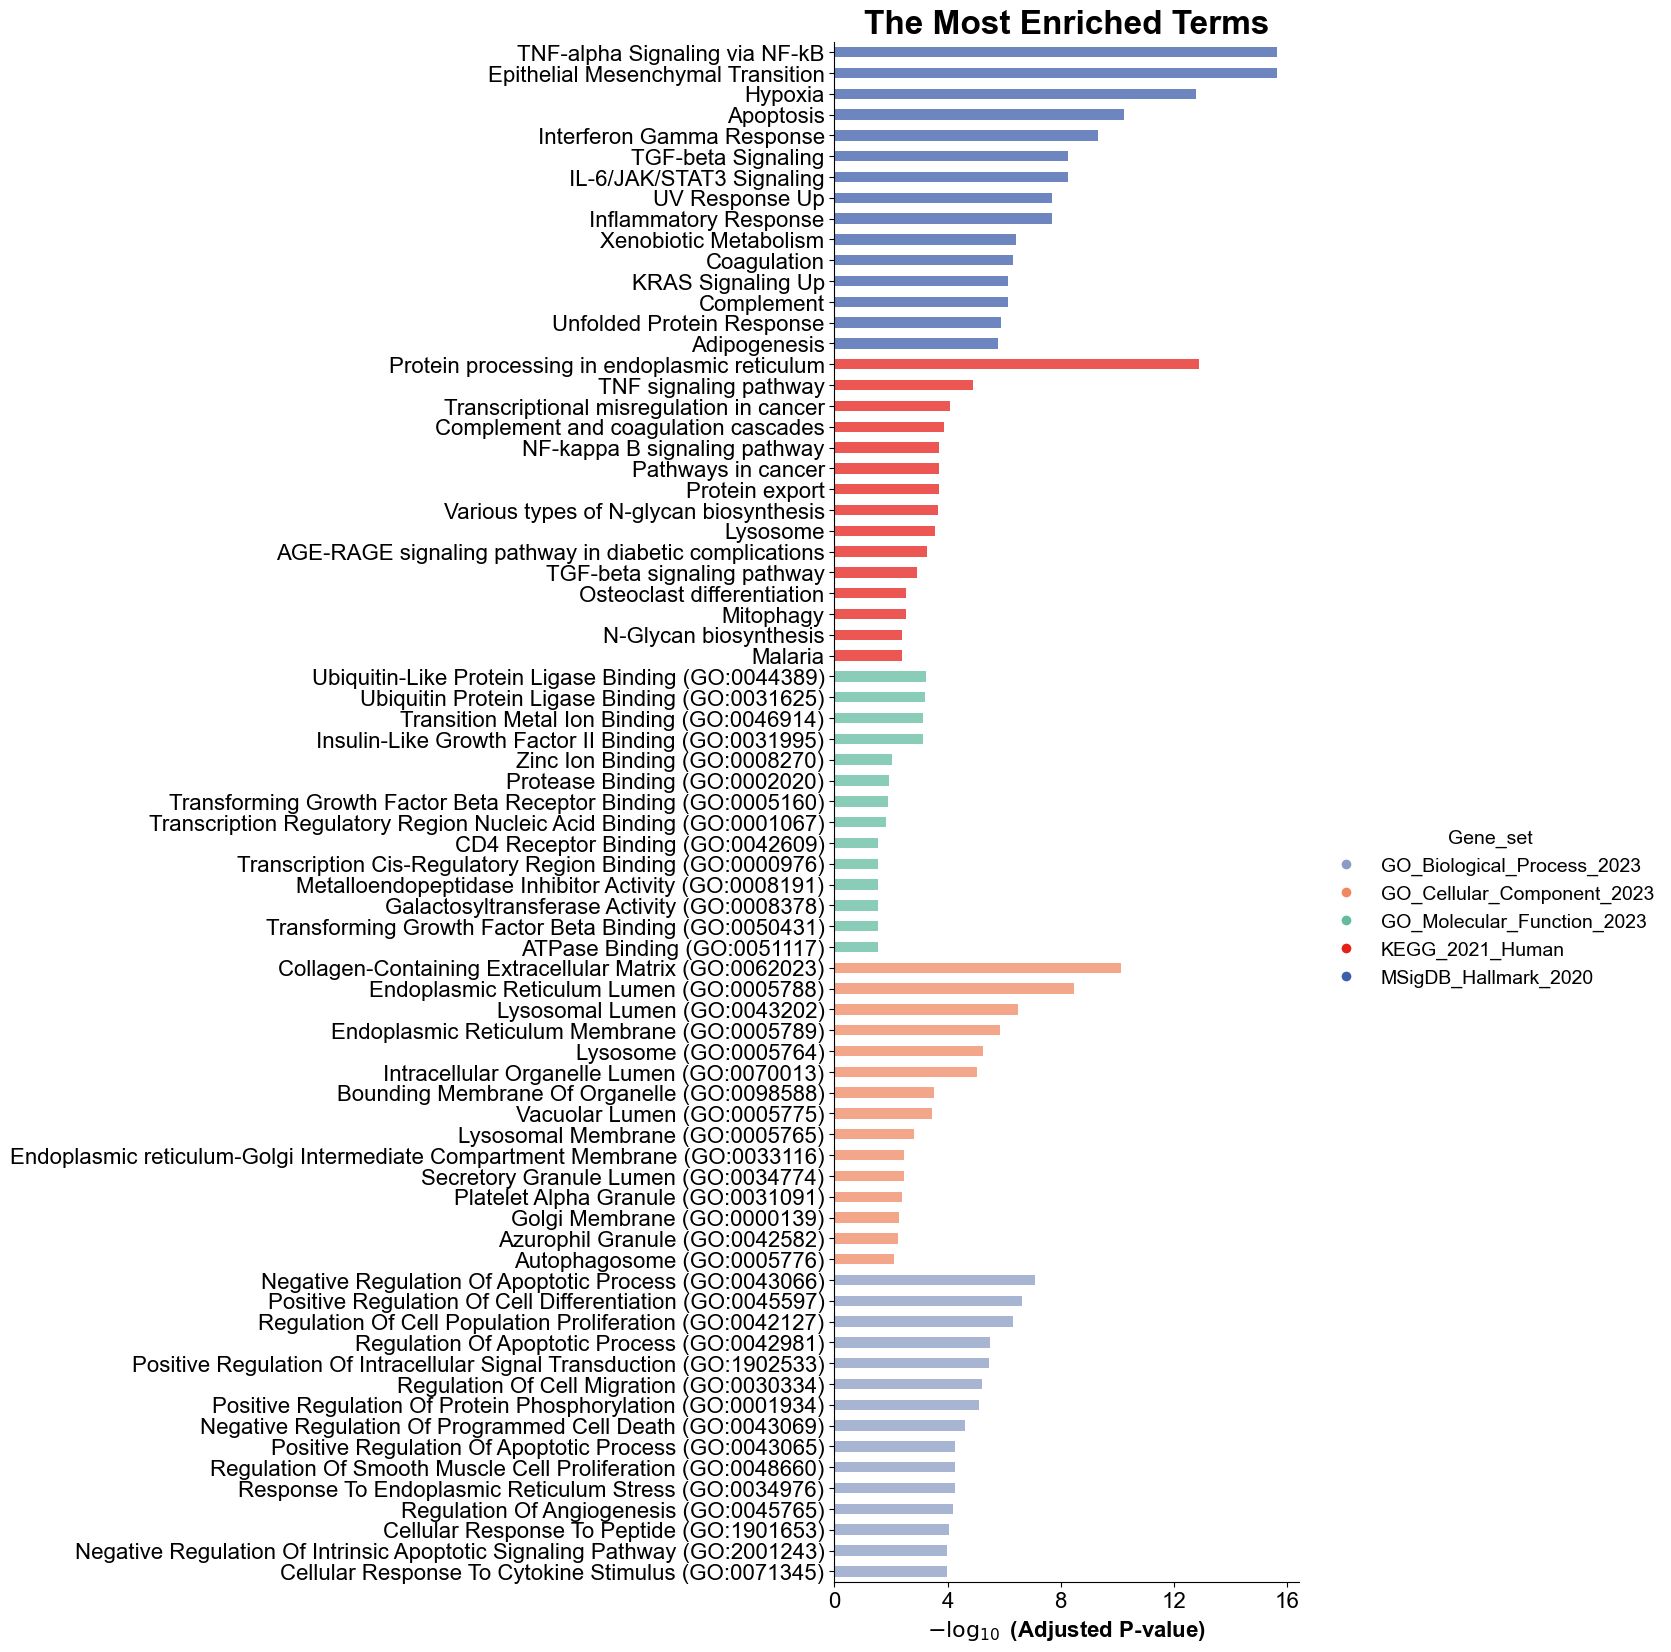

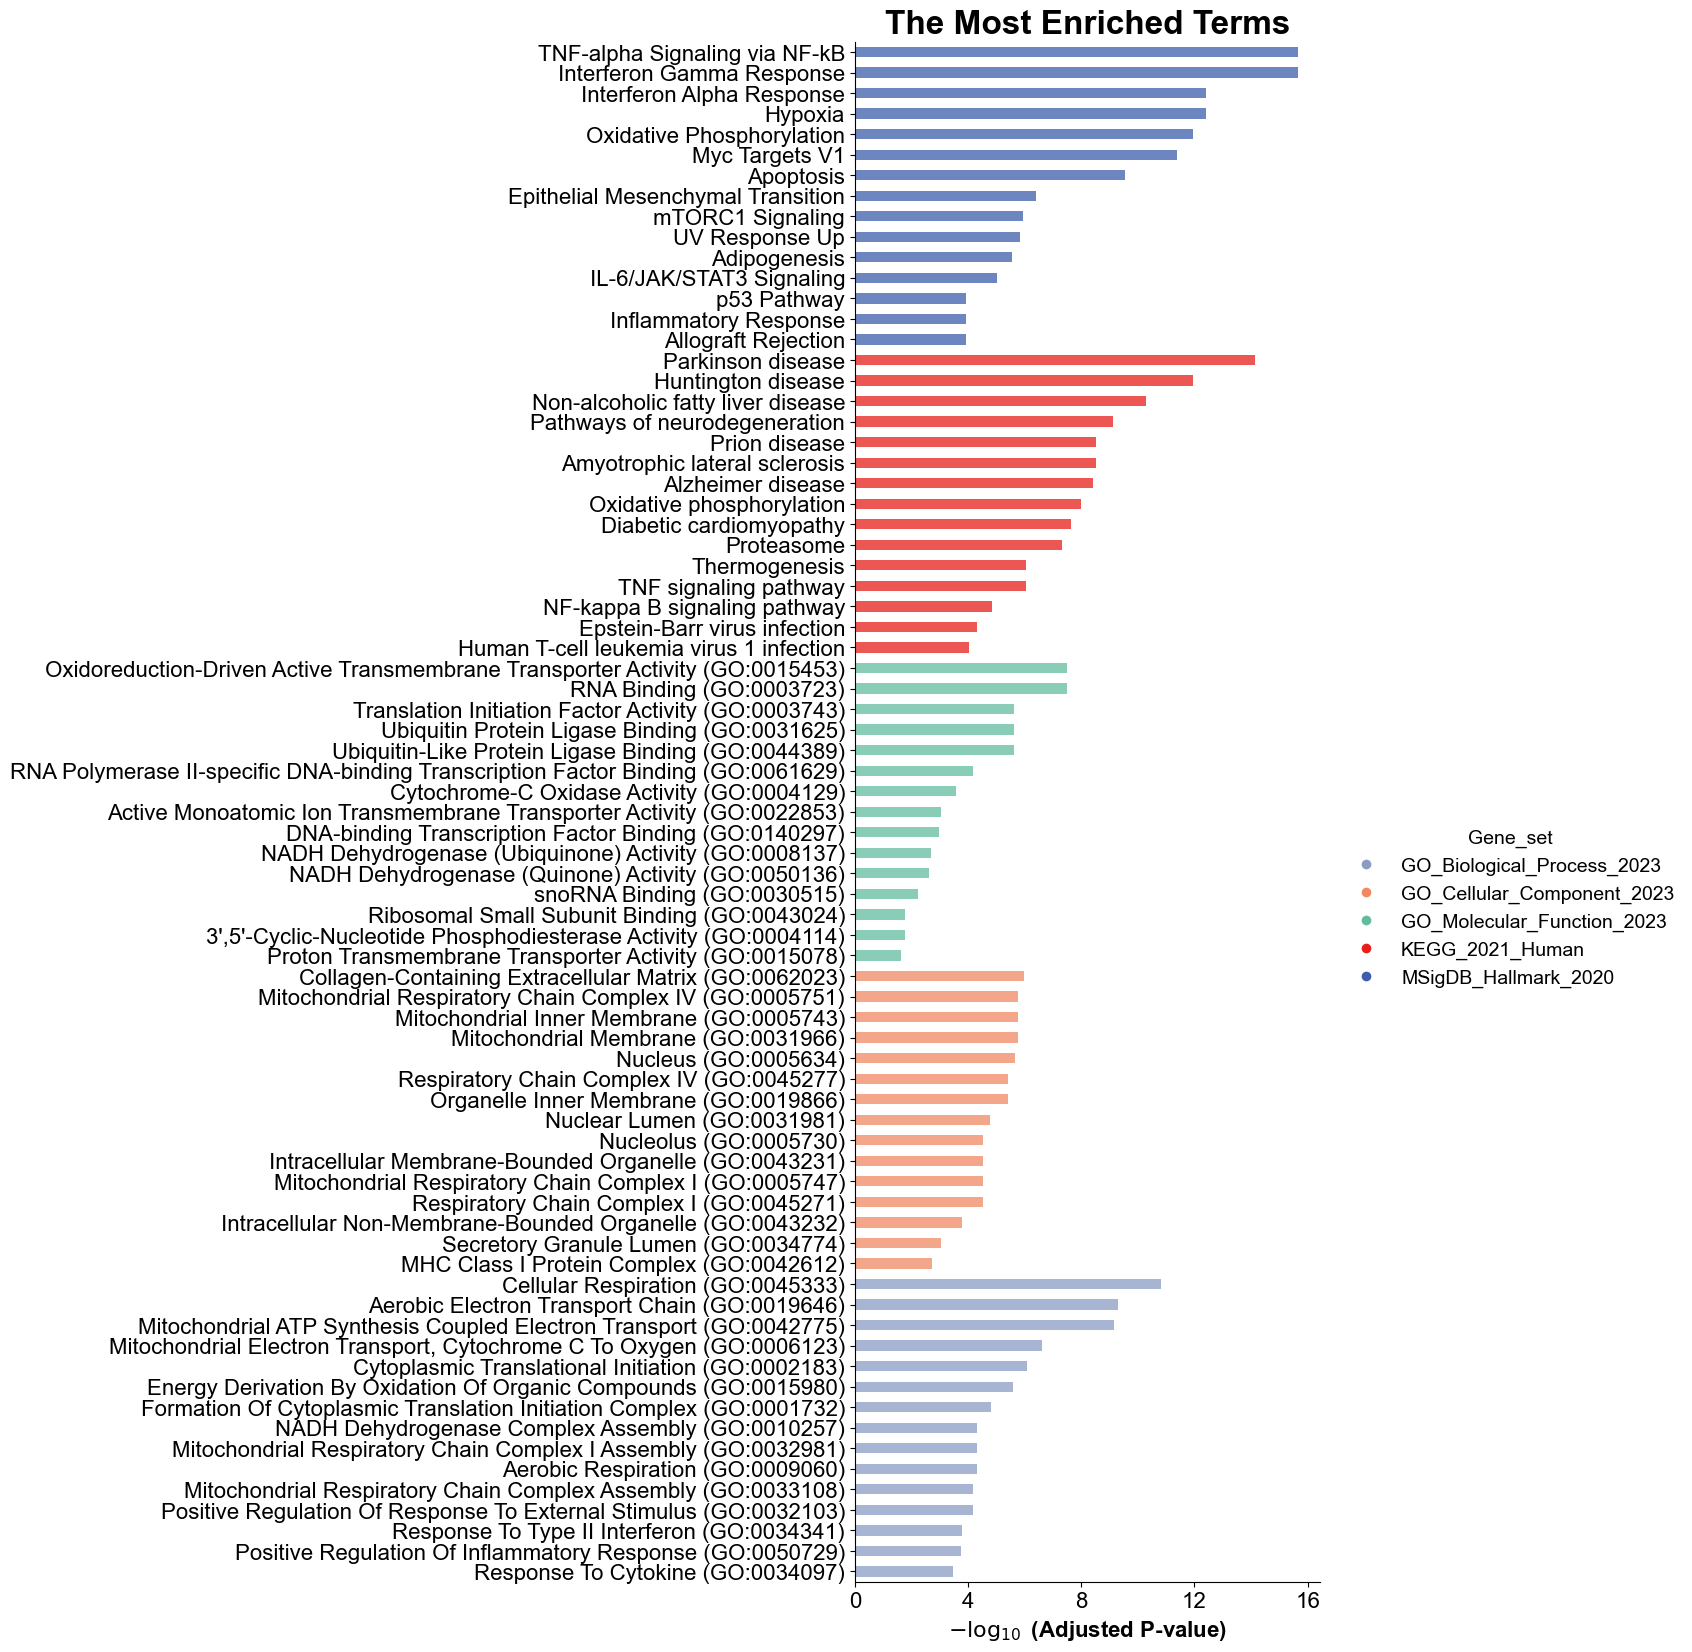

In [29]:
# Perform functional enrichment analysis (Enrichr) on specific malignant T and NK cell 
# subsets to identify significantly enriched pathways and biological processes
# Fib_degs = prep_enrichr(adata_concat, groupby='anno-Fib-number')
Fib_06, ax06 = run_enrichr_scanpy(Fib_degs,'06: MMP1+ Effector Fibro',direction='up', top_term=15, all_term=True, plot=True)
Fib_07, ax07 = run_enrichr_scanpy(Fib_degs,'07: TNC+ Matrisynthetic Fibro',direction='up', top_term=15, all_term=True, plot=True)
Fib_08, ax08 = run_enrichr_scanpy(Fib_degs,'08: IGF1+ Regenerative Fibro',direction='up', top_term=15, all_term=True, plot=True)
Fib_09, ax09 = run_enrichr_scanpy(Fib_degs,'09: CCL19+ Inflammatory Fibro',direction='up', top_term=15, all_term=True, plot=True)

In [201]:
adata_concat.write_h5ad("/home/rzh/reclustered_adata_test_42_rsc.h5ad")